# CICIDS2017 — Binary Intrusion Detection: GAN Oversampling + Ensemble + SHAP
Pipeline (29 steps): load → quality → EDA → split/scale → feature selection → **Original vs SMOTE vs WGAN-GP** baselines → tuning → ensembles → feature importance → **SHAP** → evaluation → save.

**Conventions used throughout**
- `BENIGN = 0`, `ATTACK = 1` (ATTACK is the minority / positive class).
- Every fitted object (dedupe, scaler, feature selection, GAN, SMOTE) is learned from the **training split only**. Validation and test sets never contain synthetic rows.
- Because CICIDS2017 has ~2.5M rows after cleaning, all experiments use a stratified training cap (`TRAIN_CAP`) so every scenario (Original / SMOTE / GAN) is compared on the *same* real data. Raise the caps in the CONFIG cell if you have RAM/time.

## 01 · Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib

e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%%writefile ids_utils.py
# Helper module saved next to the notebook so that the saved model / scaler can be re-loaded anywhere.
import json
from pathlib import Path
import numpy as np
import pandas as pd
import joblib


def signed_log1p(X):
    """sign(x) * log1p(|x|): tames CICIDS2017's heavy tails while keeping negative values (e.g. Init_Win_bytes = -1)."""
    X = np.asarray(X)
    if X.dtype.kind != "f":
        X = X.astype("float32")
    return np.sign(X) * np.log1p(np.abs(X))


class PrefitSoftVoting:
    """Average predict_proba of already-fitted models (avoids re-training like VotingClassifier.fit would)."""
    def __init__(self, models, weights=None):
        self.models = list(models)
        self.weights = weights
        self.classes_ = np.array([0, 1])

    def predict_proba(self, X):
        P = np.stack([m.predict_proba(X) for m in self.models], axis=0)
        return np.average(P, axis=0, weights=self.weights)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class PrefitHardVoting:
    """Majority vote of already-fitted models. predict_proba = fraction of models voting ATTACK."""
    def __init__(self, models):
        self.models = list(models)
        self.classes_ = np.array([0, 1])

    def predict_proba(self, X):
        votes = np.stack([m.predict(X) for m in self.models], axis=0).astype(float)
        p1 = votes.mean(axis=0)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


class PrefitBlendingStack:
    """Stacking by blending: a fitted meta-learner on the base models' ATTACK probabilities."""
    def __init__(self, models, meta):
        self.models = list(models)
        self.meta = meta
        self.classes_ = np.array([0, 1])

    def _meta_X(self, X):
        return np.column_stack([m.predict_proba(X)[:, 1] for m in self.models])

    def predict_proba(self, X):
        return self.meta.predict_proba(self._meta_X(X))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class IDSDetector:
    """Load the saved artefacts and score RAW CICIDS2017 flow rows (same columns as the CSVs)."""
    def __init__(self, model_dir="models"):
        d = Path(model_dir)
        self.model = joblib.load(d / "final_model.joblib")
        self.preprocessor = joblib.load(d / "preprocessor.joblib")
        self.label_encoder = joblib.load(d / "label_encoder.joblib")
        self.feature_columns = json.load(open(d / "feature_columns.json"))
        self.selected_features = json.load(open(d / "selected_features.json"))

    def _prep(self, raw_df):
        X = raw_df.copy()
        X.columns = X.columns.str.strip()
        X = X[self.feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)
        return self.preprocessor.transform(X)[self.selected_features].astype("float32")

    def predict_proba(self, raw_df):
        return self.model.predict_proba(self._prep(raw_df))[:, 1]

    def predict(self, raw_df):
        return self.label_encoder.inverse_transform(self.model.predict(self._prep(raw_df)))

Writing ids_utils.py


In [3]:
import os, gc, time, json, warnings
from pathlib import Path

import torch
import torch.nn as nn
from imblearn.over_sampling import SMOTE
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import matthews_corrcoef, ConfusionMatrixDisplay

from ids_utils import signed_log1p, PrefitSoftVoting, PrefitHardVoting, PrefitBlendingStack, IDSDetector

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

In [4]:
# ---------------- CONFIG: the only cell you need to edit to trade speed for fidelity ----------------
RANDOM_STATE   = 42
TRAIN_CAP      = 400_000   # stratified rows of the training split used in ALL scenarios (None = use everything)
BASE_TREES     = 100       # trees / boosting rounds for the un-tuned baselines
CORR_THRESHOLD = 0.95      # drop one feature of every pair with |r| above this
IMPORTANCE_CUM = 0.95      # keep features that make up this share of RF importance
GAN_ITERS      = 6000      # generator updates (each = 5 critic updates)
GAN_BATCH      = 256
GAN_LATENT     = 64
GAN_TARGET_RATIO = 1.0     # minority/majority ratio after oversampling (1.0 = fully balanced); same for SMOTE
TUNE_ROWS      = 150_000   # rows of GAN-balanced train used inside the tuning search
TUNE_VAL_ROWS  = 50_000    # real validation rows used to score each tuning trial
TUNE_ITER      = 8         # random-search trials per model
SHAP_ROWS      = 2000      # rows explained with SHAP (balanced attack / benign)
SHAP_ROWS_RF   = 500       # Random Forest SHAP is slow -> fewer rows
MODEL_DIR = Path("models"); FIG_DIR = Path("figures"); OUT_DIR = Path("outputs")
for d in (MODEL_DIR, FIG_DIR, OUT_DIR): d.mkdir(exist_ok=True)

np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def show(name=None):
    plt.tight_layout()
    if name: plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

device: cpu


## 02 · Load CICIDS2017 (all 8 CSVs)
*Edited from your version: the original attack name is now kept in `Attack_Type` (needed later for per-attack-type recall and SHAP-by-attack). `Label` is still the binary 0/1 target.*

In [5]:
from pathlib import Path

data_dir = Path(r"E:\BRM003-ML-Project\dataset folder\archive (2)\MachineLearningCVE")
csv_files = sorted(data_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CICIDS2017 CSV files found in {data_dir}")

data_df = pd.concat(
    (pd.read_csv(csv_file, skipinitialspace=True) for csv_file in csv_files),
    ignore_index=True,
)
data_df.columns = data_df.columns.str.strip()

if "Label" not in data_df.columns:
    raise ValueError("The CICIDS2017 CSV files must contain a 'Label' column")

# keep the original attack name (non-ASCII dash in 'Web Attack – ...' replaced), then binarise
label_raw = data_df["Label"].astype(str).str.strip().str.replace(r"[^\x00-\x7F]+", "-", regex=True)
data_df["Attack_Type"] = label_raw.values
data_df["Label"] = label_raw.str.upper().ne("BENIGN").astype("int8")

print(f"Loaded {len(csv_files)} CSV files; dataset shape: {data_df.shape}")
print(data_df["Label"].value_counts().rename(index={0: "BENIGN", 1: "ATTACK"}))
display(data_df.head())

Loaded 8 CSV files; dataset shape: (2830743, 80)
Label
BENIGN    2273097
ATTACK     557646
Name: count, dtype: int64


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_Type
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"110,091.7431","18,348.6238",109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"9,174.3119","9,174.3119",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"230,769.2308","38,461.5385",52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"19,230.7692","19,230.7692",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"352,941.1765","58,823.5294",34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"29,411.7647","29,411.7647",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN


## 03 · Verify dataset structure

In [6]:
FEATURE_COLS_RAW = [c for c in data_df.columns if c not in ("Label", "Attack_Type")]
print("Files loaded      :", [f.name for f in csv_files])
print("Rows x columns    :", data_df.shape)
print("Feature columns   :", len(FEATURE_COLS_RAW))
print("Has Label / Attack_Type:", "Label" in data_df, "Attack_Type" in data_df)
assert len(FEATURE_COLS_RAW) >= 70, "Unexpected number of feature columns - check the CSV files"
print("\nAttack types (raw):")
print(data_df["Attack_Type"].value_counts())

Files loaded      : ['Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']
Rows x columns    : (2830743, 80)
Feature columns   : 78
Has Label / Attack_Type: True True

Attack types (raw):
Attack_Type
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltrat

## 04 · Dataset overview

In [7]:
print("shape:", data_df.shape)
display(data_df.head())
data_df.info()

shape: (2830743, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_Type
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"110,091.7431","18,348.6238",109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"9,174.3119","9,174.3119",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"230,769.2308","38,461.5385",52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"19,230.7692","19,230.7692",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"352,941.1765","58,823.5294",34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"29,411.7647","29,411.7647",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,0,BENIGN


<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 80 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  Flow IAT Mi

In [8]:
display(data_df.describe().T)
print(data_df.dtypes.value_counts())

e:\BRM003-ML-Project\brmenv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
e:\BRM003-ML-Project\brmenv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Destination Port,"2,830,743.0000","8,071.4825","18,283.6322",0.0000,53.0000,80.0000,443.0000,"65,535.0000"
Flow Duration,"2,830,743.0000","14,785,663.9295","33,653,744.0859",-13.0000,155.0000,"31,316.0000","3,204,828.5000","119,999,998.0000"
Total Fwd Packets,"2,830,743.0000",9.3612,749.6728,1.0000,2.0000,2.0000,5.0000,"219,759.0000"
Total Backward Packets,"2,830,743.0000",10.3938,997.3883,0.0000,1.0000,2.0000,4.0000,"291,922.0000"
Total Length of Fwd Packets,"2,830,743.0000",549.3024,"9,993.5892",0.0000,12.0000,62.0000,187.0000,"12,900,000.0000"
...,...,...,...,...,...,...,...,...
Idle Mean,"2,830,743.0000","8,316,036.6272","23,630,078.5780",0.0000,0.0000,0.0000,0.0000,"120,000,000.0000"
Idle Std,"2,830,743.0000","503,843.9498","4,602,984.4807",0.0000,0.0000,0.0000,0.0000,"76,900,000.0000"
Idle Max,"2,830,743.0000","8,695,751.9846","24,366,888.3290",0.0000,0.0000,0.0000,0.0000,"120,000,000.0000"
Idle Min,"2,830,743.0000","7,920,031.0146","23,363,418.9275",0.0000,0.0000,0.0000,0.0000,"120,000,000.0000"


int64      54
float64    24
int8        1
str         1
Name: count, dtype: int64


## 05 · Data quality
Inspect first, then clean. Cleaning is row-wise/deterministic (no statistics learned), so doing it before the split does not leak information — and **removing duplicates before splitting prevents identical flows from landing in both train and test**.

In [9]:
feat = FEATURE_COLS_RAW
num = data_df[feat]

missing = num.isna().sum();                 missing = missing[missing > 0]
inf_counts = np.isinf(num).sum();           inf_counts = inf_counts[inf_counts > 0]
neg_counts = (num < 0).sum();               neg_counts = neg_counts[neg_counts > 0]
const_cols = [c for c in feat if num[c].nunique(dropna=True) <= 1]
n_dup = int(data_df.duplicated().sum())

print("Missing values per column :\n", missing if len(missing) else "none")
print("\nInfinite values per column:\n", inf_counts if len(inf_counts) else "none")
print(f"\nDuplicate rows            : {n_dup:,} ({n_dup/len(data_df):.2%})")
print("\nZero-variance columns     :", const_cols or "none")
print("\nColumns with negative values (some are legitimate, e.g. Init_Win_bytes = -1):\n", neg_counts if len(neg_counts) else "none")

Missing values per column :
 Flow Bytes/s    1358
dtype: int64

Infinite values per column:
 Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64

Duplicate rows            : 308,381 (10.89%)

Zero-variance columns     : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Columns with negative values (some are legitimate, e.g. Init_Win_bytes = -1):
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Fwd Header Length.1             35
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [10]:
# ---- cleaning ----
n0 = len(data_df)
clean_df = data_df.replace([np.inf, -np.inf], np.nan)
clean_df = clean_df.dropna(subset=feat);                              n1 = len(clean_df)   # NaN / inf rows
must_be_nonneg = [c for c in ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                              "Flow Bytes/s", "Flow Packets/s"] if c in feat]
clean_df = clean_df[(clean_df[must_be_nonneg] >= 0).all(axis=1)];       n2 = len(clean_df)   # physically invalid
clean_df = clean_df.drop_duplicates();                                   n3 = len(clean_df)   # duplicates
FEATURE_COLS = [c for c in feat if c not in const_cols]
clean_df = clean_df[FEATURE_COLS + ["Label", "Attack_Type"]].reset_index(drop=True)
clean_df[FEATURE_COLS] = clean_df[FEATURE_COLS].astype("float32")

print(f"start {n0:,} -> NaN/inf removed {n0-n1:,} -> invalid removed {n1-n2:,} -> duplicates removed {n2-n3:,} -> final {n3:,}")
print(f"features kept: {len(FEATURE_COLS)} (dropped constant: {const_cols})")
del data_df, num; gc.collect()

start 2,830,743 -> NaN/inf removed 2,867 -> invalid removed 115 -> duplicates removed 307,070 -> final 2,520,691
features kept: 70 (dropped constant: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'])


25

## 06 · Exploratory data analysis

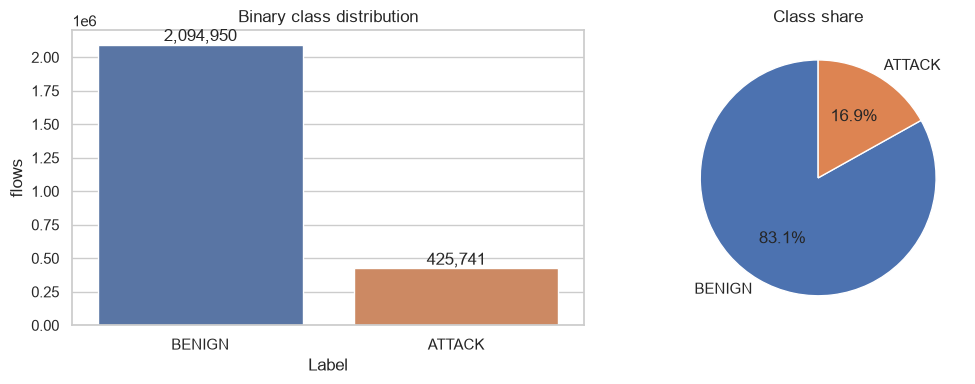

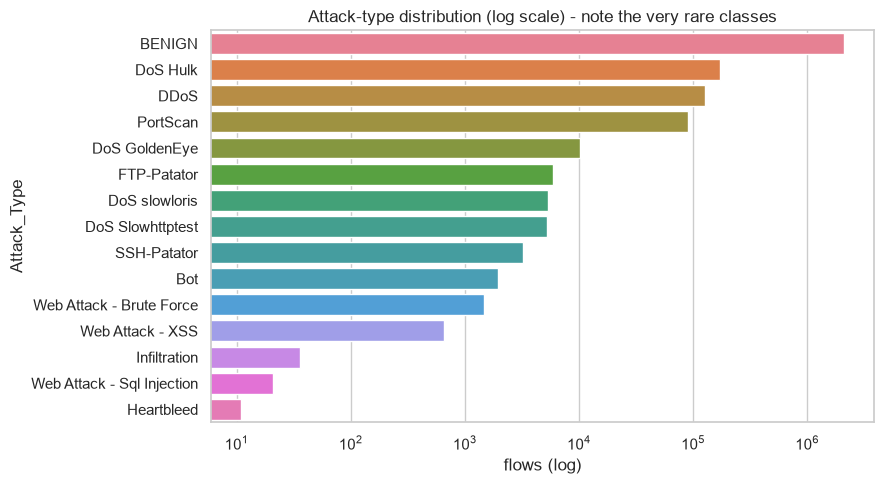

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = clean_df["Label"].map({0: "BENIGN", 1: "ATTACK"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], hue=counts.index, legend=False)
for i, v in enumerate(counts.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[0].set_title("Binary class distribution"); ax[0].set_ylabel("flows")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90); ax[1].set_title("Class share")
show("eda_binary_distribution")

at = clean_df["Attack_Type"].value_counts()
plt.figure(figsize=(9, 5)); sns.barplot(x=at.values, y=at.index, hue=at.index, legend=False); plt.xscale("log")
plt.title("Attack-type distribution (log scale) - note the very rare classes"); plt.xlabel("flows (log)")
show("eda_attack_types")

Categorical feature columns: none (CICIDS2017 flow features are all numeric)


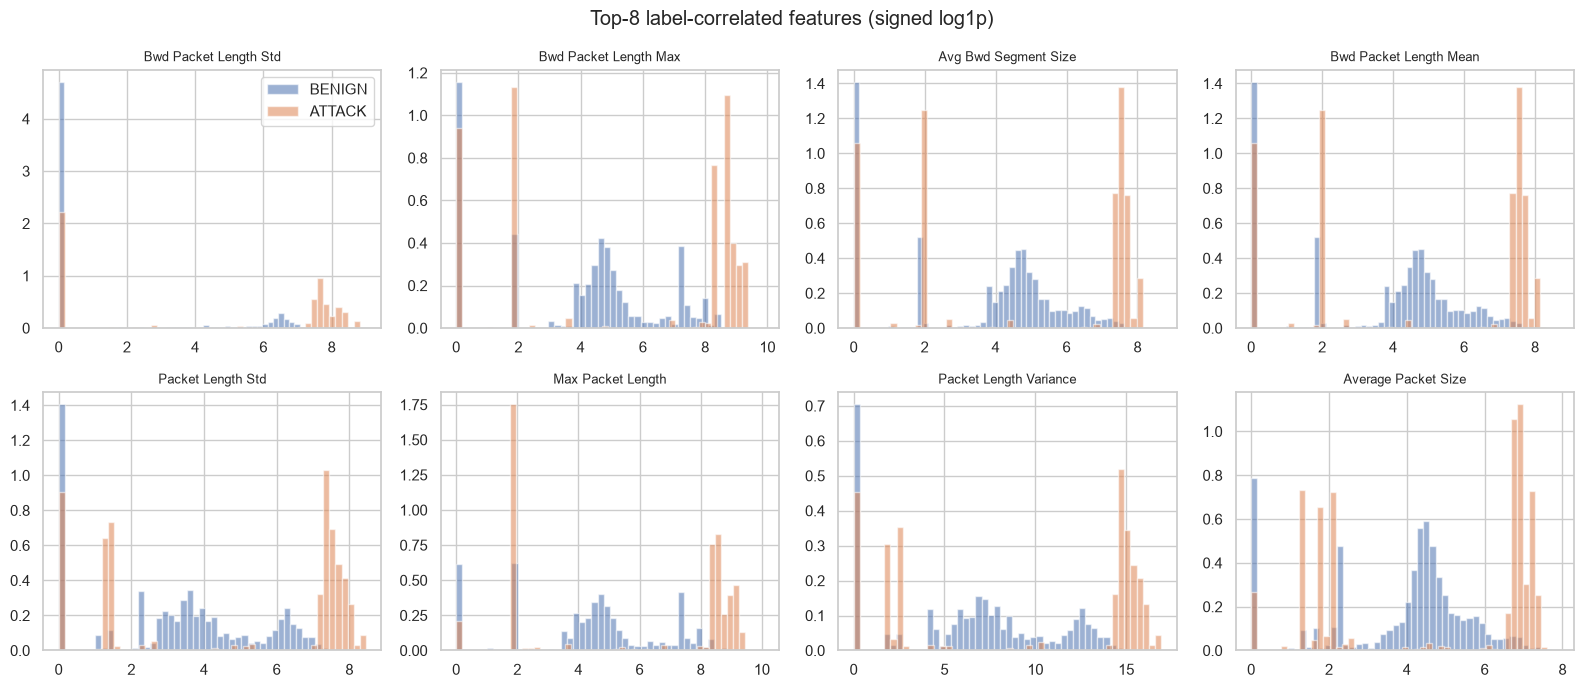

10027

In [12]:
# Categorical features
cat_cols_eda = clean_df[FEATURE_COLS].select_dtypes(exclude="number").columns.tolist()
print("Categorical feature columns:", cat_cols_eda or "none (CICIDS2017 flow features are all numeric)")

# Numerical features: the 8 most label-correlated features, benign vs attack (log scale)
sample = clean_df.sample(min(100_000, len(clean_df)), random_state=RANDOM_STATE)
top8 = sample[FEATURE_COLS].corrwith(sample["Label"]).abs().sort_values(ascending=False).head(8).index
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for a, c in zip(axes.ravel(), top8):
    for lab, name in [(0, "BENIGN"), (1, "ATTACK")]:
        a.hist(signed_log1p(sample.loc[sample["Label"] == lab, c].to_numpy()), bins=50, alpha=.55, label=name, density=True)
    a.set_title(c, fontsize=9)
axes[0, 0].legend(); fig.suptitle("Top-8 label-correlated features (signed log1p)")
show("eda_numeric_features")
del sample; gc.collect()

## 07 · Define binary target
`Label` was binarised when loading (BENIGN → 0, everything else → ATTACK → 1).

In [13]:
LABEL_NAMES = {0: "BENIGN", 1: "ATTACK"}
assert set(clean_df["Label"].unique()) == {0, 1}
print(clean_df["Label"].map(LABEL_NAMES).value_counts())
print(pd.crosstab(clean_df["Attack_Type"], clean_df["Label"].map(LABEL_NAMES)))

Label
BENIGN    2094950
ATTACK     425741
Name: count, dtype: int64
Label                       ATTACK   BENIGN
Attack_Type                                
BENIGN                           0  2094950
Bot                           1948        0
DDoS                        128014        0
DoS GoldenEye                10286        0
DoS Hulk                    172846        0
DoS Slowhttptest              5228        0
DoS slowloris                 5385        0
FTP-Patator                   5931        0
Heartbleed                      11        0
Infiltration                    36        0
PortScan                     90694        0
SSH-Patator                   3219        0
Web Attack - Brute Force      1470        0
Web Attack - Sql Injection      21        0
Web Attack - XSS               652        0


## 08 · X / y separation

In [14]:
X = clean_df[FEATURE_COLS].copy()
y_raw = clean_df["Label"].to_numpy()
attack_type = clean_df["Attack_Type"].copy()      # metadata only - never a model input
print("X:", X.shape, "| y:", y_raw.shape)

X: (2520691, 70) | y: (2520691,)


## 09 · Identify data types

In [15]:
numerical_features  = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print(f"numerical: {len(numerical_features)} | categorical: {len(categorical_features)}")

numerical: 70 | categorical: 0


## 10 · Encode features
One-hot only if categorical columns exist (none for CICIDS2017). The target is label-encoded with an explicit order so that **BENIGN = 0, ATTACK = 1**.

In [16]:
if categorical_features:
    X = pd.get_dummies(X, columns=categorical_features, dtype="float32")
    print("one-hot encoded ->", X.shape)
else:
    print("No categorical features -> one-hot encoding not needed.")

label_encoder = LabelEncoder()
label_encoder.classes_ = np.array(["BENIGN", "ATTACK"])      # fixed order (plain .fit would make ATTACK = 0)
y = label_encoder.transform(pd.Series(y_raw).map(LABEL_NAMES))
assert (y == y_raw).all()
print("classes:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))
del clean_df; gc.collect()

No categorical features -> one-hot encoding not needed.
classes: {np.str_('BENIGN'): np.int64(0), np.str_('ATTACK'): np.int64(1)}


20

## 11 · Train / validation / test split (stratified 70 / 15 / 15)
Test set is locked until step 26. The training split is then capped (`TRAIN_CAP`) with stratification so every experiment uses identical real training data.

In [17]:
X_tmp, X_test, y_tmp, y_test, at_tmp, at_test = train_test_split(
    X, y, attack_type, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train_full, X_val, y_train_full, y_val, at_train_full, at_val = train_test_split(
    X_tmp, y_tmp, at_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=RANDOM_STATE)

if TRAIN_CAP and len(X_train_full) > TRAIN_CAP:
    X_train, _, y_train, _, at_train, _ = train_test_split(
        X_train_full, y_train_full, at_train_full, train_size=TRAIN_CAP, stratify=y_train_full, random_state=RANDOM_STATE)
else:
    X_train, y_train, at_train = X_train_full, y_train_full, at_train_full

for n_, a_ in [("train_full", y_train_full), ("train (used)", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{n_:13s} {len(a_):>9,}   attack share = {a_.mean():.2%}")
for v in ("X", "X_tmp"): globals().pop(v, None)
gc.collect()

train_full    1,764,483   attack share = 16.89%
train (used)    400,000   attack share = 16.89%
validation      378,104   attack share = 16.89%
test            378,104   attack share = 16.89%


0

## 12 · Feature scaling
`signed log1p` (tames the extreme tails of byte/packet/IAT features) followed by `StandardScaler`, **fit on the training split only**. Tree models are invariant to this monotone transform; it matters for Logistic Regression, the GAN and SMOTE's distance metric.

In [18]:
preprocessor = Pipeline([
    ("signed_log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
]).set_output(transform="pandas")

X_train_s = preprocessor.fit_transform(X_train).astype("float32")
X_val_s   = preprocessor.transform(X_val).astype("float32")
X_test_s  = preprocessor.transform(X_test).astype("float32")
print("scaled train  mean|std (first 5 features):", X_train_s.mean().head().round(3).tolist(), X_train_s.std().head().round(3).tolist())

scaled train  mean|std (first 5 features): [0.0, -0.0, -0.0, -0.0, -0.0] [1.0, 1.0, 1.0, 1.0, 1.0]


## 13 · Binary class-imbalance analysis

In [19]:
def imbalance_table(y_, name):
    c = pd.Series(y_).map(LABEL_NAMES).value_counts()
    return pd.DataFrame({"count": c, "percent": (c / c.sum() * 100).round(2)}).rename_axis(name)

display(imbalance_table(y_train, "train (used)"))
minority_label = int(pd.Series(y_train).value_counts().idxmin())
n_min, n_maj = int((y_train == minority_label).sum()), int((y_train != minority_label).sum())
print(f"Minority class: {LABEL_NAMES[minority_label]} | imbalance ratio (majority:minority) = {n_maj/n_min:.2f} : 1")
print("\nAttack types inside the training set (the real imbalance problem is here):")
display(pd.Series(at_train).value_counts().rename("train_count").to_frame())

,count,percent
train (used),,
BENIGN,332440,83.1100
ATTACK,67560,16.8900


Minority class: ATTACK | imbalance ratio (majority:minority) = 4.92 : 1

Attack types inside the training set (the real imbalance problem is here):


,train_count
Attack_Type,
BENIGN,332440
DoS Hulk,27410
DDoS,20283
PortScan,14376
DoS GoldenEye,1670
FTP-Patator,1007
DoS slowloris,855
DoS Slowhttptest,814
SSH-Patator,500


## 14 · Feature selection
Correlation pruning → Random-Forest importance. Both computed on **training data only**.

30 features dropped for |r| > 0.95; 40 remain
selected 26 features covering 95.2% of RF importance


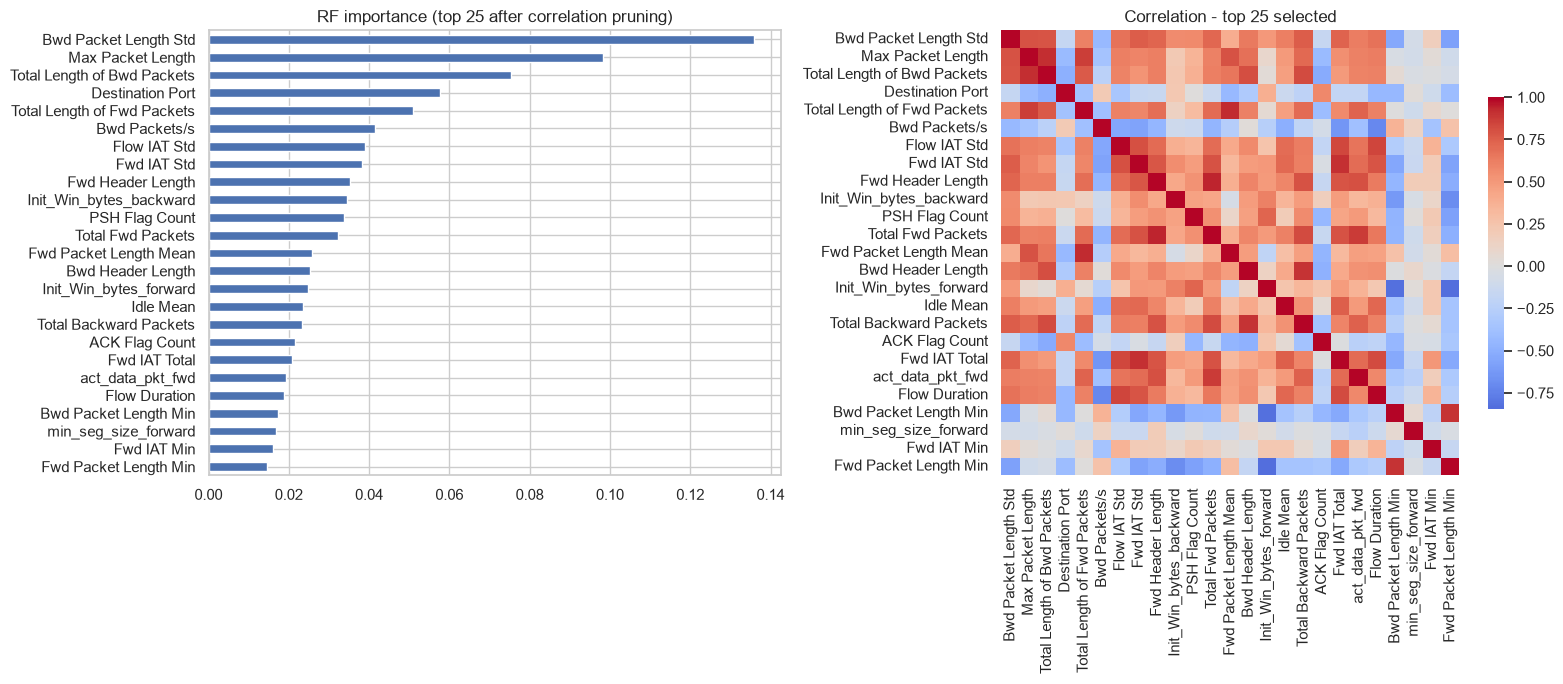

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
selected_features,Bwd Packet Length Std,Max Packet Length,Total Length of Bwd Packets,Destination Port,Total Length of Fwd Packets,Bwd Packets/s,Flow IAT Std,Fwd IAT Std,Fwd Header Length,Init_Win_bytes_backward,PSH Flag Count,Total Fwd Packets,Fwd Packet Length Mean,Bwd Header Length,Init_Win_bytes_forward,Idle Mean,Total Backward Packets,ACK Flag Count,Fwd IAT Total,act_data_pkt_fwd,Flow Duration,Bwd Packet Length Min,min_seg_size_forward,Fwd IAT Min,Fwd Packet Length Min,Flow Bytes/s


In [20]:
s = X_train_s.sample(min(100_000, len(X_train_s)), random_state=RANDOM_STATE)
corr = s.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop_corr = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]
kept = [c for c in X_train_s.columns if c not in drop_corr]
print(f"{len(drop_corr)} features dropped for |r| > {CORR_THRESHOLD}; {len(kept)} remain")

rf_sel = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
idx = X_train_s.sample(min(200_000, len(X_train_s)), random_state=RANDOM_STATE).index
rf_sel.fit(X_train_s.loc[idx, kept], pd.Series(y_train, index=X_train_s.index).loc[idx])
imp = pd.Series(rf_sel.feature_importances_, index=kept).sort_values(ascending=False)
n_keep = max(20, int(np.searchsorted(imp.cumsum().values, IMPORTANCE_CUM)) + 1)
selected_features = imp.index[:n_keep].tolist()
print(f"selected {len(selected_features)} features covering {imp.iloc[:n_keep].sum():.1%} of RF importance")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
imp.head(25)[::-1].plot.barh(ax=ax[0]); ax[0].set_title("RF importance (top 25 after correlation pruning)")
top_c = imp.index[:25]
sns.heatmap(s[top_c].corr(), cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .7}); ax[1].set_title("Correlation - top 25 selected")
show("feature_selection")

X_train_sel, X_val_sel, X_test_sel = X_train_s[selected_features], X_val_s[selected_features], X_test_s[selected_features]
display(pd.Series(selected_features, name="selected_features").to_frame().T)

## 15 · BASELINE — original (imbalanced) data
Shared helpers: one `evaluate` function and a `registry` of every fitted model so later steps can reuse them.

In [21]:
results, registry = [], {}          # results: one dict per (scenario, model, split); registry: fitted models

def metrics_from_proba(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(
        accuracy=accuracy_score(y_true, pred),
        precision=precision_score(y_true, pred, zero_division=0),
        recall=recall_score(y_true, pred, zero_division=0),
        f1=f1_score(y_true, pred, zero_division=0),
        macro_f1=f1_score(y_true, pred, average="macro", zero_division=0),
        roc_auc=roc_auc_score(y_true, proba),
        pr_auc=average_precision_score(y_true, proba),
        mcc=matthews_corrcoef(y_true, pred),
        fp=int(((pred == 1) & (y_true == 0)).sum()), fn=int(((pred == 0) & (y_true == 1)).sum()),
    )

def evaluate(model, X_, y_, scenario, name, split):
    return dict(scenario=scenario, model=name, split=split, **metrics_from_proba(y_, model.predict_proba(X_)[:, 1]))

def fit_and_log(model, name, scenario, Xtr, ytr):
    t0 = time.time(); model.fit(Xtr, ytr); dt = time.time() - t0
    registry[(scenario, name)] = model
    row = evaluate(model, X_val_sel, y_val, scenario, name, "validation"); row["fit_time_s"] = round(dt, 1)
    results.append(row); print(f"[{scenario}] {name:<28s} F1={row['f1']:.4f}  PR-AUC={row['pr_auc']:.4f}  MCC={row['mcc']:.4f}  ({dt:.0f}s)")
    return model

def log_ensemble(names, scenario, label="Ensemble (Soft Voting)"):
    ens = PrefitSoftVoting([registry[(scenario, n)] for n in names])
    registry[(scenario, label)] = ens
    results.append(evaluate(ens, X_val_sel, y_val, scenario, label, "validation"))
    r = results[-1]; print(f"[{scenario}] {label:<28s} F1={r['f1']:.4f}  PR-AUC={r['pr_auc']:.4f}  MCC={r['mcc']:.4f}")

def make_tree_models(n=BASE_TREES):
    return {
        "Random Forest": RandomForestClassifier(n_estimators=n, n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=n * 3, learning_rate=0.1, max_depth=8, tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=RANDOM_STATE),
        "LightGBM": LGBMClassifier(n_estimators=n * 3, learning_rate=0.1, num_leaves=63, subsample_freq=1, subsample=0.9, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
    }
TREE_NAMES = ["Random Forest", "XGBoost", "LightGBM"]

SC = "Original"
fit_and_log(LogisticRegression(max_iter=1000, n_jobs=-1, random_state=RANDOM_STATE), "Logistic Regression", SC, X_train_sel, y_train)
fit_and_log(DecisionTreeClassifier(random_state=RANDOM_STATE), "Decision Tree", SC, X_train_sel, y_train)
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_sel, y_train)
log_ensemble(TREE_NAMES, SC)       # extra row: soft-voting of the 3 original tree models (used in steps 25-27)

e:\BRM003-ML-Project\brmenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[Original] Logistic Regression          F1=0.9064  PR-AUC=0.9468  MCC=0.8883  (1s)
[Original] Decision Tree                F1=0.9954  PR-AUC=0.9916  MCC=0.9945  (4s)
[Original] Random Forest                F1=0.9964  PR-AUC=0.9981  MCC=0.9956  (9s)
[Original] XGBoost                      F1=0.9976  PR-AUC=0.9998  MCC=0.9971  (4s)
[Original] LightGBM                     F1=0.9970  PR-AUC=0.9998  MCC=0.9964  (4s)
[Original] Ensemble (Soft Voting)       F1=0.9973  PR-AUC=0.9998  MCC=0.9967


## 16 · SMOTE baseline

In [22]:
t0 = time.time()
smote = SMOTE(sampling_strategy=GAN_TARGET_RATIO, k_neighbors=5, random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train)
print(f"SMOTE: {len(X_train_sel):,} -> {len(X_train_smote):,} rows in {time.time()-t0:.0f}s | attack share {y_train_smote.mean():.1%}")

SC = "SMOTE"
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_smote, y_train_smote)
log_ensemble(TREE_NAMES, SC)

SMOTE: 400,000 -> 664,880 rows in 4s | attack share 50.0%
[SMOTE] Random Forest                F1=0.9965  PR-AUC=0.9978  MCC=0.9958  (16s)
[SMOTE] XGBoost                      F1=0.9970  PR-AUC=0.9998  MCC=0.9964  (5s)
[SMOTE] LightGBM                     F1=0.9967  PR-AUC=0.9998  MCC=0.9961  (6s)
[SMOTE] Ensemble (Soft Voting)       F1=0.9971  PR-AUC=0.9998  MCC=0.9965


## 17 · GAN oversampling (WGAN-GP)
Why WGAN-GP: the from-scratch vanilla GAN in your NSL-KDD run collapsed early; the Wasserstein loss + gradient penalty is the standard fix. The GAN is trained **only on ATTACK rows of the training split** (scaled, selected features) and generates synthetic attacks up to the target ratio.

*Note:* "ATTACK" bundles very different behaviours (DoS, PortScan, Brute-force…). One unconditional generator can favour the dominant modes — the validation cell below checks this, and a conditional version per attack family is the natural upgrade.

minority samples: (67560, 26)
iter    600/6000  critic=  -2.368  gen=   2.210  W-dist=  2.701  (28s)
iter   1200/6000  critic=  -1.946  gen=   1.318  W-dist=  2.183  (53s)
iter   1800/6000  critic=  -1.480  gen=   0.821  W-dist=  1.670  (76s)
iter   2400/6000  critic=  -1.348  gen=   0.062  W-dist=  1.521  (100s)
iter   3000/6000  critic=  -1.211  gen=  -0.294  W-dist=  1.368  (124s)
iter   3600/6000  critic=  -1.177  gen=  -0.630  W-dist=  1.313  (148s)
iter   4200/6000  critic=  -1.101  gen=  -0.255  W-dist=  1.227  (172s)
iter   4800/6000  critic=  -0.963  gen=  -0.809  W-dist=  1.112  (196s)
iter   5400/6000  critic=  -0.929  gen=  -0.604  W-dist=  1.066  (220s)
iter   6000/6000  critic=  -0.934  gen=  -0.957  W-dist=  1.037  (244s)


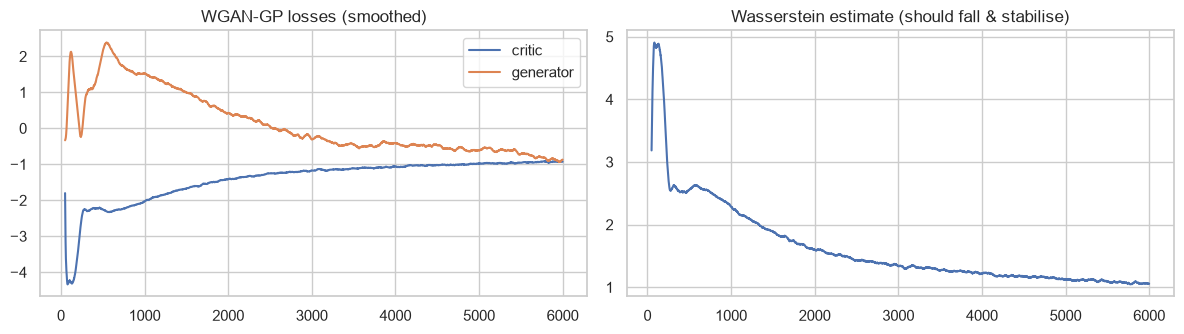

In [23]:
# ---- 17a. prepare minority data ----
X_min = X_train_sel[y_train == 1].to_numpy(dtype=np.float32)
n_feat = X_min.shape[1]
X_min_t = torch.from_numpy(X_min).to(device)
print("minority samples:", X_min.shape)

# ---- 17b. WGAN-GP ----
class Generator(nn.Module):
    def __init__(s, z=GAN_LATENT, h=256, out=n_feat):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(z, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, out))
    def forward(s, z): return s.net(z)

class Critic(nn.Module):
    def __init__(s, inp=n_feat, h=256):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(inp, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, 1))
    def forward(s, x): return s.net(x)

def gradient_penalty(critic, real, fake):
    a = torch.rand(real.size(0), 1, device=device)
    xi = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(critic(xi).sum(), xi, create_graph=True)[0]
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

G, D = Generator().to(device), Critic().to(device)
optG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
optD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.9))
N_CRITIC, LAMBDA_GP = 5, 10.0
hist = {"critic": [], "gen": [], "w_dist": []}

t0 = time.time()
for it in range(1, GAN_ITERS + 1):
    for _ in range(N_CRITIC):
        real = X_min_t[torch.randint(0, len(X_min_t), (GAN_BATCH,), device=device)]
        fake = G(torch.randn(GAN_BATCH, GAN_LATENT, device=device)).detach()
        d_real, d_fake = D(real).mean(), D(fake).mean()
        loss_d = d_fake - d_real + LAMBDA_GP * gradient_penalty(D, real, fake)
        optD.zero_grad(); loss_d.backward(); optD.step()
    loss_g = -D(G(torch.randn(GAN_BATCH, GAN_LATENT, device=device))).mean()
    optG.zero_grad(); loss_g.backward(); optG.step()
    hist["critic"].append(loss_d.item()); hist["gen"].append(loss_g.item()); hist["w_dist"].append((d_real - d_fake).item())
    if it % max(1, GAN_ITERS // 10) == 0:
        print(f"iter {it:>6}/{GAN_ITERS}  critic={loss_d.item():8.3f}  gen={loss_g.item():8.3f}  W-dist={hist['w_dist'][-1]:7.3f}  ({time.time()-t0:.0f}s)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(pd.Series(hist["critic"]).rolling(50).mean(), label="critic"); ax[0].plot(pd.Series(hist["gen"]).rolling(50).mean(), label="generator"); ax[0].legend(); ax[0].set_title("WGAN-GP losses (smoothed)")
ax[1].plot(pd.Series(hist["w_dist"]).rolling(50).mean()); ax[1].set_title("Wasserstein estimate (should fall & stabilise)")
show("gan_training")

In [24]:
# ---- 17c. generate synthetic ATTACK samples ----
n_needed = max(0, int(round((y_train == 0).sum() * GAN_TARGET_RATIO)) - int((y_train == 1).sum()))
G.eval(); chunks = []
with torch.no_grad():
    for i in range(0, n_needed, 50_000):
        b = min(50_000, n_needed - i)
        chunks.append(G(torch.randn(b, GAN_LATENT, device=device)).cpu().numpy())
X_syn = np.clip(np.vstack(chunks), X_min.min(0), X_min.max(0)).astype("float32")     # keep inside the real range
print("synthetic attack samples:", X_syn.shape)

synthetic attack samples: (264880, 26)


mean KS statistic per feature : 0.251 (median 0.190, max 0.531)   -> lower is better
mean |corr_real - corr_syn|   : 0.060   -> lower is better
real-vs-synthetic RF AUC      : 1.000   -> closer to 0.5 is better (1.0 = trivially fake)
nearest-real distance         : synthetic 0.831 vs real-to-real 0.068   (synthetic << real would signal memorisation)


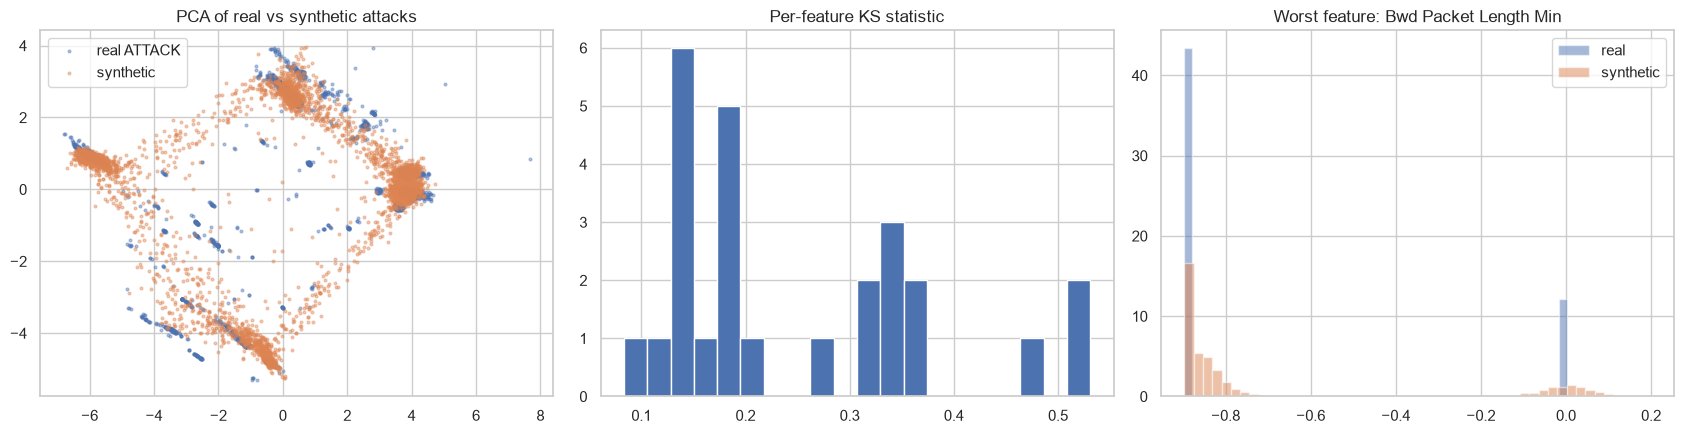

In [25]:
# ---- 17d. validate synthetic samples (real attacks vs synthetic attacks) ----
rng = np.random.default_rng(RANDOM_STATE)
ri = rng.choice(len(X_min), min(5000, len(X_min)), replace=False); si = rng.choice(len(X_syn), min(5000, len(X_syn)), replace=False)
R, S = X_min[ri], X_syn[si]

ks = np.array([ks_2samp(R[:, j], S[:, j]).statistic for j in range(n_feat)])
corr_gap = np.nan_to_num(np.abs(np.corrcoef(R.T) - np.corrcoef(S.T))).mean()

# discriminative test: can a classifier tell real from fake? (AUC 0.5 = indistinguishable)
Z = np.vstack([R, S]); zl = np.r_[np.ones(len(R)), np.zeros(len(S))]
Ztr, Zte, ltr, lte = train_test_split(Z, zl, test_size=0.3, stratify=zl, random_state=RANDOM_STATE)
disc_auc = roc_auc_score(lte, RandomForestClassifier(100, n_jobs=-1, random_state=RANDOM_STATE).fit(Ztr, ltr).predict_proba(Zte)[:, 1])

# memorisation / realism: distance to nearest real attack, synthetic vs real-to-real (leave-one-out)
nn_ = NearestNeighbors(n_neighbors=2).fit(X_min[rng.choice(len(X_min), min(20_000, len(X_min)), replace=False)])
d_syn = nn_.kneighbors(S[:2000], n_neighbors=1)[0].ravel()
d_real = nn_.kneighbors(R[:2000], n_neighbors=2)[0][:, 1]

print(f"mean KS statistic per feature : {ks.mean():.3f} (median {np.median(ks):.3f}, max {ks.max():.3f})   -> lower is better")
print(f"mean |corr_real - corr_syn|   : {corr_gap:.3f}   -> lower is better")
print(f"real-vs-synthetic RF AUC      : {disc_auc:.3f}   -> closer to 0.5 is better (1.0 = trivially fake)")
print(f"nearest-real distance         : synthetic {d_syn.mean():.3f} vs real-to-real {d_real.mean():.3f}   (synthetic << real would signal memorisation)")

pca = PCA(2, random_state=RANDOM_STATE).fit(R)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (M_, nm) in zip(ax[:1], [(R, "real")]): pass
pr, ps = pca.transform(R), pca.transform(S)
ax[0].scatter(*pr.T, s=4, alpha=.4, label="real ATTACK"); ax[0].scatter(*ps.T, s=4, alpha=.4, label="synthetic"); ax[0].legend(); ax[0].set_title("PCA of real vs synthetic attacks")
ax[1].hist(ks, bins=20); ax[1].set_title("Per-feature KS statistic")
worst = np.argsort(ks)[-1]; ax[2].hist(R[:, worst], bins=50, alpha=.5, density=True, label="real"); ax[2].hist(S[:, worst], bins=50, alpha=.5, density=True, label="synthetic")
ax[2].set_title(f"Worst feature: {selected_features[worst]}"); ax[2].legend()
show("gan_validation")

In [26]:
# ---- 17e. combine real + synthetic (training data only) ----
X_train_gan = pd.concat([X_train_sel, pd.DataFrame(X_syn, columns=selected_features)], ignore_index=True)
y_train_gan = np.r_[y_train, np.ones(len(X_syn), dtype=int)]
print(f"GAN-balanced train: {len(X_train_gan):,} rows | attack share {y_train_gan.mean():.1%}  (real {len(X_train_sel):,} + synthetic {len(X_syn):,})")

GAN-balanced train: 664,880 rows | attack share 50.0%  (real 400,000 + synthetic 264,880)


## 18 · GAN-based binary classification (default hyper-parameters)

In [27]:
SC = "GAN"
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_gan, y_train_gan)
log_ensemble(TREE_NAMES, SC)

[GAN] Random Forest                F1=0.9964  PR-AUC=0.9980  MCC=0.9956  (28s)
[GAN] XGBoost                      F1=0.9976  PR-AUC=0.9998  MCC=0.9971  (6s)
[GAN] LightGBM                     F1=0.9970  PR-AUC=0.9998  MCC=0.9964  (7s)
[GAN] Ensemble (Soft Voting)       F1=0.9972  PR-AUC=0.9998  MCC=0.9966


## 19 · Hyper-parameter tuning (RF, XGBoost, LightGBM)
Random search on the **GAN-balanced training data**, but scored on a **real validation subset** (`PredefinedSplit`) — ordinary k-fold CV would score on synthetic rows too and reward the GAN's own artefacts. The test set is still untouched.

In [28]:
Xt, _, yt, _ = train_test_split(X_train_gan, y_train_gan, train_size=min(TUNE_ROWS, len(X_train_gan) - 1), stratify=y_train_gan, random_state=RANDOM_STATE)
Xv, _, yv, _ = train_test_split(X_val_sel, y_val, train_size=min(TUNE_VAL_ROWS, len(X_val_sel) - 1), stratify=y_val, random_state=RANDOM_STATE)
X_search, y_search = pd.concat([Xt, Xv]), np.r_[yt, yv]
cv = PredefinedSplit(np.r_[-np.ones(len(Xt)), np.zeros(len(Xv))])

spaces = {
    "Random Forest": dict(n_estimators=[100, 200, 300], max_depth=[None, 20, 30], min_samples_leaf=[1, 2, 5], max_features=["sqrt", 0.3]),
    "XGBoost": dict(n_estimators=[200, 400, 600], max_depth=[6, 8, 10], learning_rate=[0.05, 0.1, 0.2], subsample=[0.7, 0.9, 1.0], colsample_bytree=[0.6, 0.8, 1.0]),
    "LightGBM": dict(n_estimators=[200, 400, 600], num_leaves=[31, 63, 127], learning_rate=[0.05, 0.1, 0.2], min_child_samples=[20, 50, 100], subsample=[0.7, 0.9, 1.0], colsample_bytree=[0.6, 0.8, 1.0]),
}
best_params = {}
for name, base in make_tree_models().items():
    t0 = time.time()
    rs = RandomizedSearchCV(base, spaces[name], n_iter=TUNE_ITER, scoring="average_precision", cv=cv, refit=False, random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_search, y_search)
    best_params[name] = rs.best_params_
    print(f"{name:14s} best PR-AUC {rs.best_score_:.4f} in {time.time()-t0:.0f}s -> {rs.best_params_}")
json.dump(best_params, open(OUT_DIR / "best_params.json", "w"), indent=2, default=str)

Random Forest  best PR-AUC 0.9998 in 87s -> {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
XGBoost        best PR-AUC 0.9998 in 29s -> {'subsample': 0.7, 'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
LightGBM       best PR-AUC 0.9998 in 14s -> {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


In [29]:
# refit the tuned models on the full GAN-balanced training set
SC = "GAN + Tuned"
for name, base in make_tree_models().items():
    fit_and_log(base.set_params(**best_params[name]), name, SC, X_train_gan, y_train_gan)

[GAN + Tuned] Random Forest                F1=0.9971  PR-AUC=0.9998  MCC=0.9965  (53s)
[GAN + Tuned] XGBoost                      F1=0.9975  PR-AUC=0.9998  MCC=0.9970  (13s)
[GAN + Tuned] LightGBM                     F1=0.9972  PR-AUC=0.9998  MCC=0.9966  (3s)


## 20 · Ensemble classification (hard voting, soft voting, blending stack)
The blending stack trains a logistic-regression meta-learner on the base models' probabilities. Meta-features come from the **real validation set**; its validation score below is out-of-fold (5-fold) so it is not over-optimistic.

In [30]:
SC = "GAN + Tuned"
base_models = [registry[(SC, n)] for n in TREE_NAMES]

hard = PrefitHardVoting(base_models); registry[(SC, "Ensemble (Hard Voting)")] = hard
results.append(evaluate(hard, X_val_sel, y_val, SC, "Ensemble (Hard Voting)", "validation"))
log_ensemble(TREE_NAMES, SC, "Ensemble (Soft Voting)")

P_val = np.column_stack([m.predict_proba(X_val_sel)[:, 1] for m in base_models])
meta = LogisticRegression(max_iter=1000)
oof = cross_val_predict(meta, P_val, y_val, cv=5, method="predict_proba")[:, 1]
results.append(dict(scenario=SC, model="Ensemble (Stacking)", split="validation", **metrics_from_proba(y_val, oof)))
stack = PrefitBlendingStack(base_models, meta.fit(P_val, y_val)); registry[(SC, "Ensemble (Stacking)")] = stack

ens_val = pd.DataFrame([r for r in results if r["scenario"] == SC and r["model"].startswith("Ensemble")]).set_index("model")
display(ens_val[["accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc", "pr_auc", "mcc", "fp", "fn"]])

FINAL_NAME = ens_val["mcc"].idxmax()
final_model = registry[(SC, FINAL_NAME)]
print(f"\nFinal ensemble chosen by validation MCC: {FINAL_NAME}")

[GAN + Tuned] Ensemble (Soft Voting)       F1=0.9974  PR-AUC=0.9998  MCC=0.9969


,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc,mcc,fp,fn
model,,,,,,,,,,
Ensemble (Hard Voting),0.9991,0.9970,0.9979,0.9975,0.9985,0.9990,0.9963,0.9969,194,131
Ensemble (Soft Voting),0.9991,0.9969,0.9979,0.9974,0.9985,1.0000,0.9998,0.9969,195,131
Ensemble (Stacking),0.9991,0.9972,0.9976,0.9974,0.9984,0.9999,0.9997,0.9969,179,151



Final ensemble chosen by validation MCC: Ensemble (Hard Voting)


## 21 · Feature importance (RF / XGBoost / LightGBM, tuned, GAN-trained)

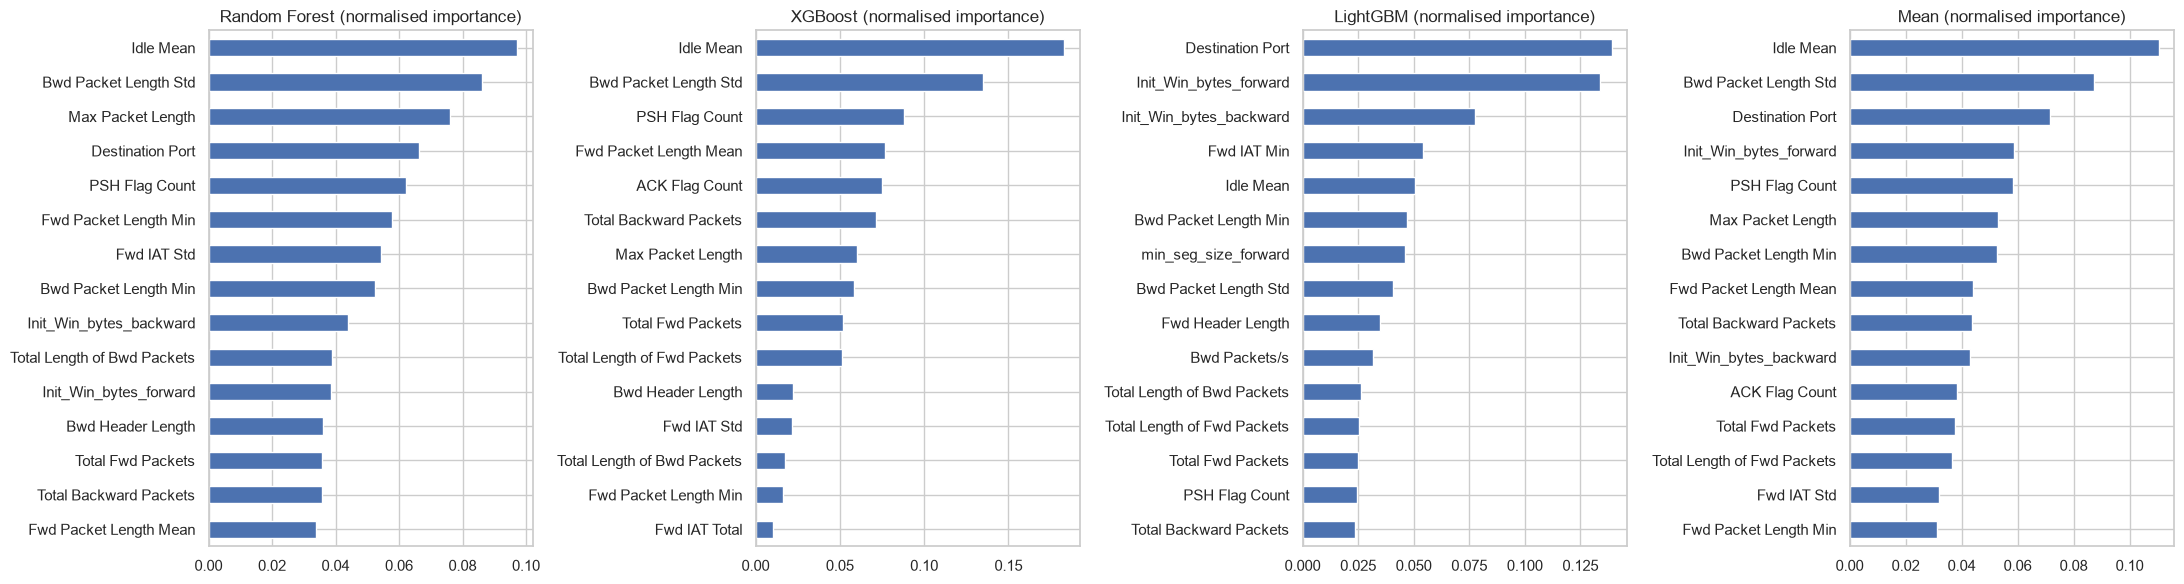

,Random Forest,XGBoost,LightGBM,Mean
Idle Mean,0.0973,0.1832,0.0505,0.1103
Bwd Packet Length Std,0.0861,0.1346,0.0408,0.0872
Destination Port,0.0664,0.0091,0.1390,0.0715
Init_Win_bytes_forward,0.0387,0.0034,0.1337,0.0586
PSH Flag Count,0.0623,0.0881,0.0247,0.0583
Max Packet Length,0.0759,0.0601,0.0232,0.0531
Bwd Packet Length Min,0.0525,0.0587,0.0468,0.0527
Fwd Packet Length Mean,0.0338,0.0768,0.0213,0.0440
Total Backward Packets,0.0358,0.0716,0.0237,0.0437
Init_Win_bytes_backward,0.0440,0.0071,0.0775,0.0429


In [31]:
SC = "GAN + Tuned"
fi = pd.DataFrame({n: registry[(SC, n)].feature_importances_ for n in TREE_NAMES}, index=selected_features)
fi = fi / fi.sum()
fi["Mean"] = fi.mean(axis=1)
fi = fi.sort_values("Mean", ascending=False)
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, n in zip(ax, TREE_NAMES + ["Mean"]):
    fi[n].sort_values().tail(15).plot.barh(ax=a); a.set_title(f"{n} (normalised importance)")
show("feature_importance")
fi.to_csv(OUT_DIR / "feature_importance.csv"); display(fi.head(15))

## 22 · SHAP explainability (TreeExplainer)
SHAP is computed for each tree model on a **balanced sample of the test set** (half ATTACK, half BENIGN) — so plots describe behaviour on that sample, not the natural 80/20 mix. The ensemble's global importance is the average of each model's normalised mean |SHAP| (models live in different output spaces: probability for RF, log-odds for XGBoost/LightGBM).

In [32]:
def shap_attack(model, X_):
    exp = shap.TreeExplainer(model)
    sv = exp.shap_values(X_)
    if isinstance(sv, list): sv = sv[1]                 # older SHAP: list per class
    elif getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]  # newer SHAP: (n, features, classes)
    return np.asarray(sv), float(np.ravel(exp.expected_value)[-1])

rng = np.random.default_rng(RANDOM_STATE)
ia = np.flatnonzero(y_test == 1); ib = np.flatnonzero(y_test == 0)
pick = rng.permutation(np.r_[rng.choice(ia, min(SHAP_ROWS // 2, len(ia)), replace=False), rng.choice(ib, min(SHAP_ROWS // 2, len(ib)), replace=False)])
X_shap, y_shap, at_shap = X_test_sel.iloc[pick].reset_index(drop=True), y_test[pick], at_test.iloc[pick].reset_index(drop=True)

SC = "GAN + Tuned"; shap_vals, shap_base = {}, {}
for n in TREE_NAMES:
    Xn = X_shap.iloc[: SHAP_ROWS_RF] if n == "Random Forest" else X_shap
    t0 = time.time(); shap_vals[n], shap_base[n] = shap_attack(registry[(SC, n)], Xn)
    print(f"{n}: SHAP computed on {len(Xn):,} rows in {time.time()-t0:.0f}s")

Random Forest: SHAP computed on 500 rows in 23s
XGBoost: SHAP computed on 2,000 rows in 1s
LightGBM: SHAP computed on 2,000 rows in 0s


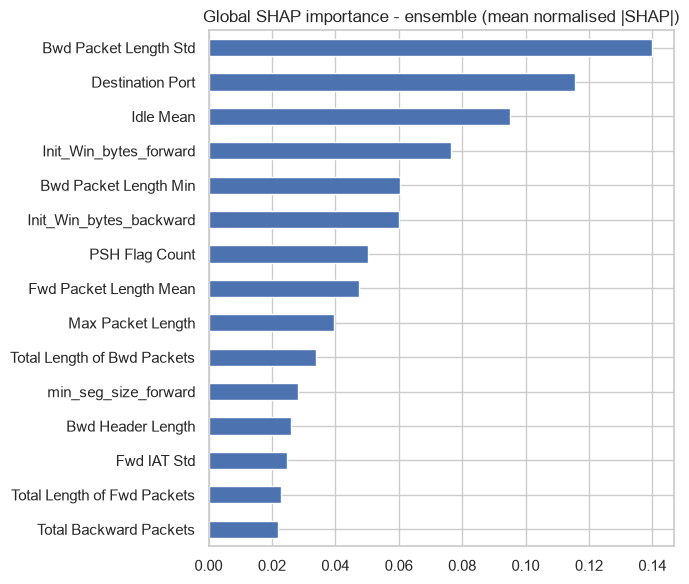

C:\Users\Surya\AppData\Local\Temp\ipykernel_14060\1627319912.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals["XGBoost"], X_shap, max_display=15, show=False); plt.title("SHAP summary - XGBoost (all sampled flows)")


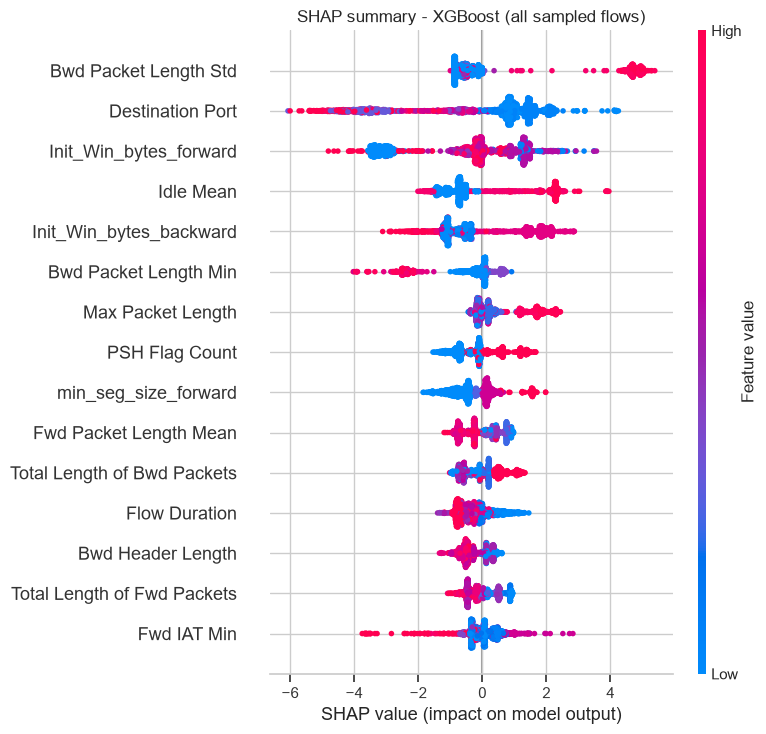

In [33]:
# ---- global explanation ----
mean_abs = pd.DataFrame({n: np.abs(shap_vals[n]).mean(0) for n in TREE_NAMES}, index=selected_features)
mean_abs = mean_abs / mean_abs.sum()
mean_abs["Ensemble (avg)"] = mean_abs.mean(axis=1)
mean_abs = mean_abs.sort_values("Ensemble (avg)", ascending=False)
mean_abs["Ensemble (avg)"].head(15)[::-1].plot.barh(figsize=(7, 6), title="Global SHAP importance - ensemble (mean normalised |SHAP|)")
show("shap_global_bar"); mean_abs.to_csv(OUT_DIR / "shap_global.csv")

shap.summary_plot(shap_vals["XGBoost"], X_shap, max_display=15, show=False); plt.title("SHAP summary - XGBoost (all sampled flows)")
show("shap_summary_xgb")

C:\Users\Surya\AppData\Local\Temp\ipykernel_14060\2755090034.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals["XGBoost"][m_att], X_shap[m_att], max_display=15, show=False); plt.title("SHAP - what pushes a true ATTACK flow towards 'ATTACK' (XGBoost)")


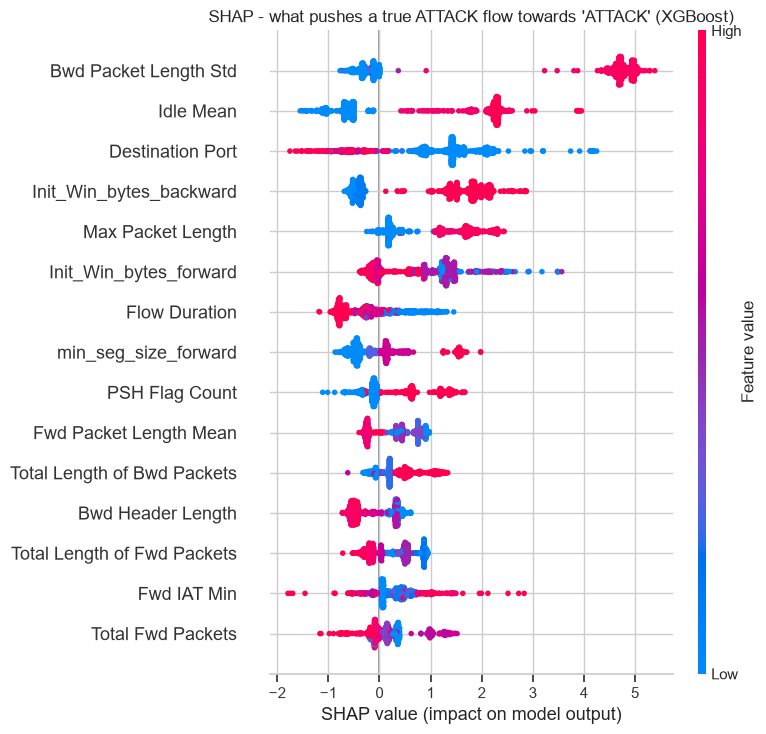

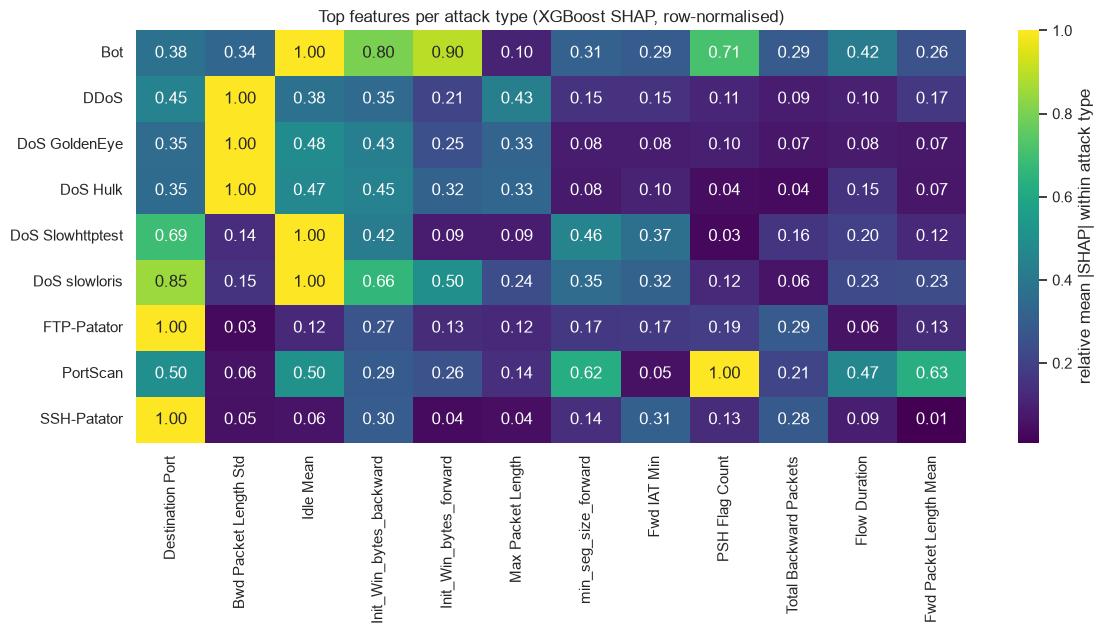

In [34]:
# ---- attack-class explanation ----
m_att = y_shap == 1
shap.summary_plot(shap_vals["XGBoost"][m_att], X_shap[m_att], max_display=15, show=False); plt.title("SHAP - what pushes a true ATTACK flow towards 'ATTACK' (XGBoost)")
show("shap_attack_only")

# which features drive detection of each attack family? (mean |SHAP| inside each attack type)
sv_x = pd.DataFrame(np.abs(shap_vals["XGBoost"]), columns=selected_features)
by_type = sv_x[m_att].groupby(at_shap[m_att].values).mean()
by_type = by_type[by_type.index.map(lambda t: (at_shap[m_att] == t).sum() >= 5)]
top_f = by_type.mean().sort_values(ascending=False).head(12).index
plt.figure(figsize=(12, max(3, .5 * len(by_type) + 2)))
sns.heatmap(by_type[top_f].div(by_type[top_f].max(axis=1), axis=0), cmap="viridis", annot=True, fmt=".2f", cbar_kws={"label": "relative mean |SHAP| within attack type"})
plt.title("Top features per attack type (XGBoost SHAP, row-normalised)")
show("shap_by_attack_type")

True positive (attack caught): row 0, attack type = DoS Hulk, P(attack) = 1.000


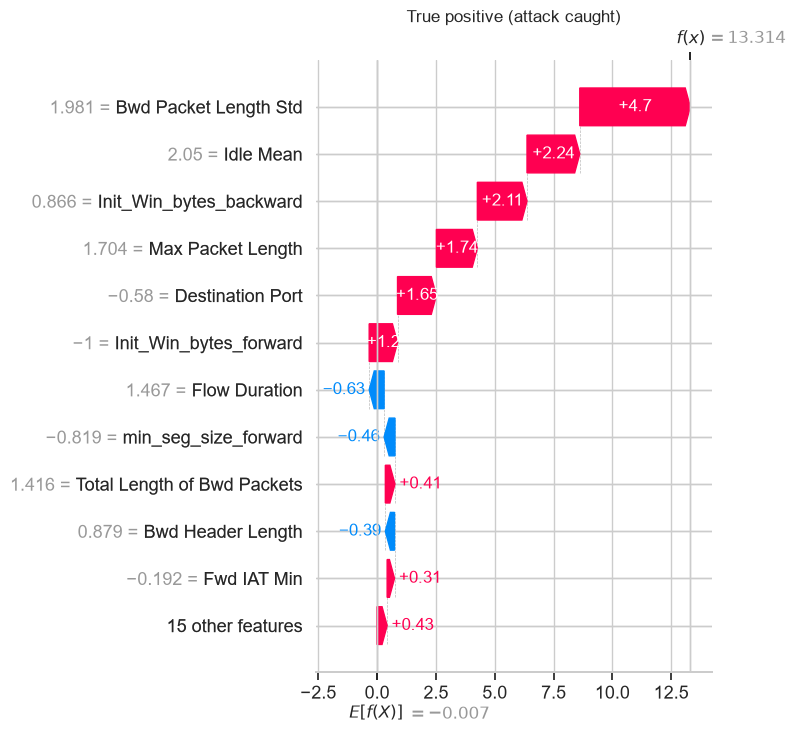

False negative (attack missed): row 338, attack type = Bot, P(attack) = 0.338


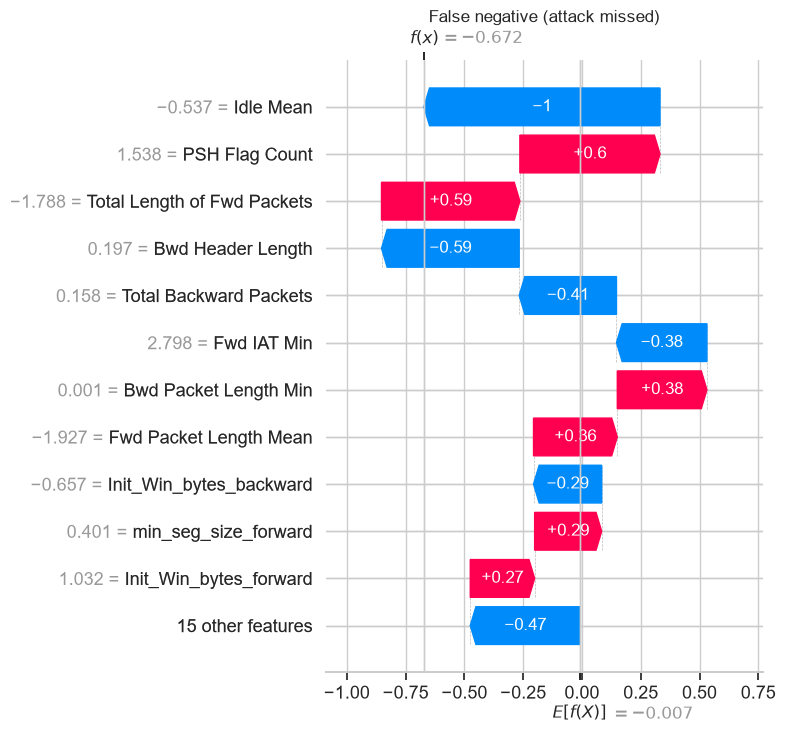

True negative (benign): row 2, attack type = BENIGN, P(attack) = 0.000


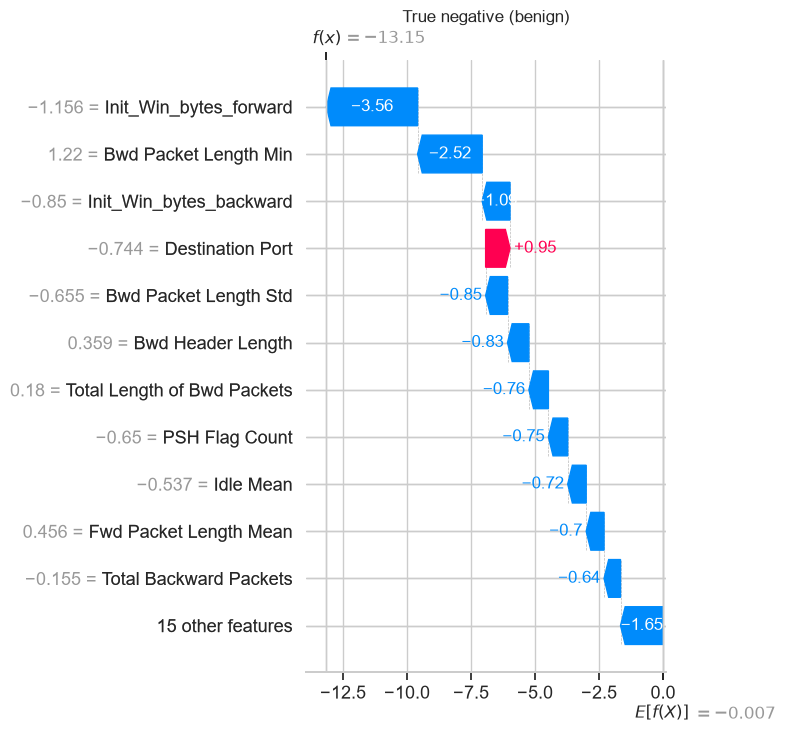

In [35]:
# ---- local explanations (XGBoost) : one caught attack, one missed attack (if any), one benign flow ----
xgb_m = registry[("GAN + Tuned", "XGBoost")]
pred_shap = xgb_m.predict(X_shap)
cases = {"True positive (attack caught)": np.flatnonzero((y_shap == 1) & (pred_shap == 1)),
         "False negative (attack missed)": np.flatnonzero((y_shap == 1) & (pred_shap == 0)),
         "True negative (benign)": np.flatnonzero((y_shap == 0) & (pred_shap == 0))}
for title, ids in cases.items():
    if len(ids) == 0:
        print(f"{title}: no such case in the sample"); continue
    i = int(ids[0]); print(f"{title}: row {i}, attack type = {at_shap[i]}, P(attack) = {xgb_m.predict_proba(X_shap.iloc[[i]])[0, 1]:.3f}")
    shap.plots.waterfall(shap.Explanation(values=shap_vals["XGBoost"][i], base_values=shap_base["XGBoost"], data=X_shap.iloc[i].to_numpy(), feature_names=selected_features), max_display=12, show=False)
    plt.title(title); show(f"shap_local_{title.split()[0].lower()}_{title.split()[1].lower()}")

## 23 · Binary classification evaluation — final ensemble (validation set)

,Ensemble (Hard Voting)
accuracy,0.9991
precision,0.9970
recall,0.9979
f1,0.9975
macro_f1,0.9985
roc_auc,0.9990
pr_auc,0.9963
mcc,0.9969
fp,194.0000
fn,131.0000


              precision    recall  f1-score   support

      BENIGN     0.9996    0.9994    0.9995    314243
      ATTACK     0.9970    0.9979    0.9975     63861

    accuracy                         0.9991    378104
   macro avg     0.9983    0.9987    0.9985    378104
weighted avg     0.9991    0.9991    0.9991    378104



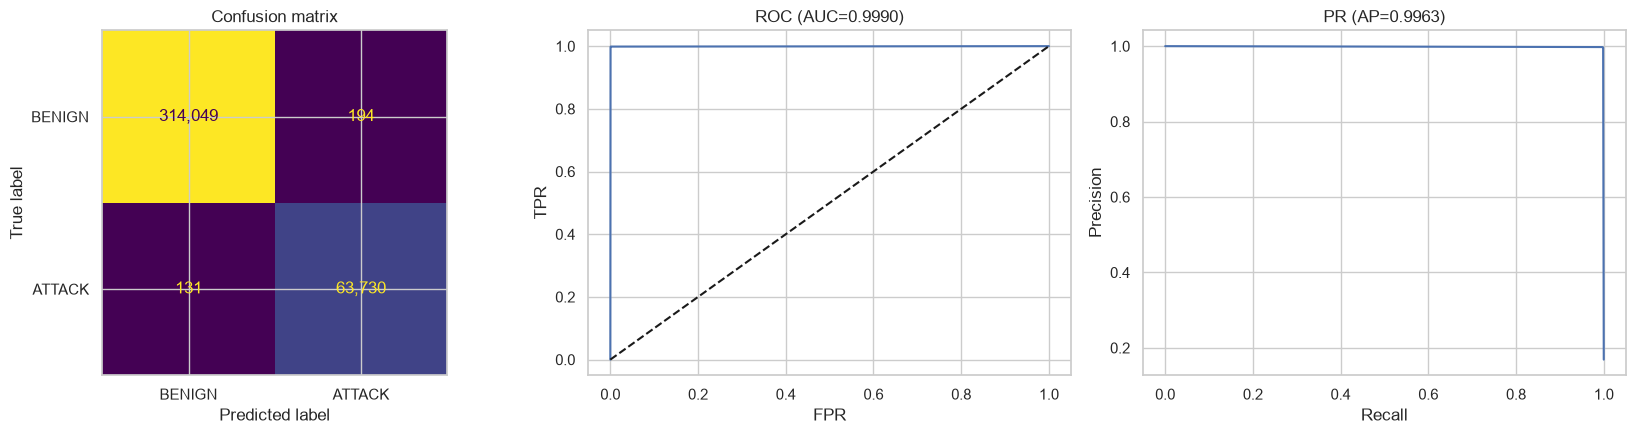

In [36]:
y_val_proba = final_model.predict_proba(X_val_sel)[:, 1]; y_val_pred = (y_val_proba >= 0.5).astype(int)
display(pd.Series(metrics_from_proba(y_val, y_val_proba), name=FINAL_NAME).to_frame())
print(classification_report(y_val, y_val_pred, target_names=["BENIGN", "ATTACK"], digits=4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["BENIGN", "ATTACK"], ax=ax[0], colorbar=False, values_format=",d"); ax[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_val, y_val_proba); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(title=f"ROC (AUC={roc_auc_score(y_val, y_val_proba):.4f})", xlabel="FPR", ylabel="TPR")
p_, r_, _ = precision_recall_curve(y_val, y_val_proba); ax[2].plot(r_, p_); ax[2].set(title=f"PR (AP={average_precision_score(y_val, y_val_proba):.4f})", xlabel="Recall", ylabel="Precision")
show("eval_final_validation")

## 24 · Per-class evaluation
BENIGN vs ATTACK, plus **detection rate per original attack type** — this is where oversampling can genuinely help (rare attacks), even when the binary score is already saturated.

In [37]:
rep = pd.DataFrame(classification_report(y_val, y_val_pred, target_names=["BENIGN", "ATTACK"], output_dict=True, digits=4)).T.loc[["BENIGN", "ATTACK"]]
display(rep)

def per_type_detection(models, X_, y_, at_):
    """share of flows of each attack type predicted ATTACK (= recall); for BENIGN it is the specificity."""
    out = {}
    for label, m in models.items():
        hit = pd.Series(m.predict(X_) == 1, index=at_.index if hasattr(at_, "index") else None)
        out[label] = np.where(pd.Series(at_).values == "BENIGN", 1 - hit.values, hit.values)
    df = pd.DataFrame(out); df["type"] = pd.Series(at_).values
    g = df.groupby("type").mean(); g.insert(0, "support", df.groupby("type").size())
    return g.sort_values("support")

scen_models = {"Original": registry[("Original", "Ensemble (Soft Voting)")], "SMOTE": registry[("SMOTE", "Ensemble (Soft Voting)")],
               "GAN": registry[("GAN", "Ensemble (Soft Voting)")], "GAN + Tuned (final)": final_model}
det_val = per_type_detection(scen_models, X_val_sel, y_val, at_val.reset_index(drop=True))
print("Detection rate per attack type - VALIDATION (BENIGN row = specificity):")
display(det_val.style.format({c: "{:.3f}" for c in det_val.columns if c != "support"}).background_gradient(subset=[c for c in det_val.columns if c != "support"], cmap="RdYlGn", vmin=0.5, vmax=1))

,precision,recall,f1-score,support
BENIGN,0.9996,0.9994,0.9995,"314,243.0000"
ATTACK,0.9970,0.9979,0.9975,"63,861.0000"


Detection rate per attack type - VALIDATION (BENIGN row = specificity):


,support,Original,SMOTE,GAN,GAN + Tuned (final)
type,,,,,
Web Attack - Sql Injection,2,1.000,1.000,1.000,1.000
Infiltration,6,0.500,0.500,0.167,0.167
Web Attack - XSS,92,0.989,0.989,0.978,0.967
Web Attack - Brute Force,218,0.995,0.995,0.995,0.991
Bot,282,0.727,0.883,0.723,0.699
SSH-Patator,506,1.000,1.000,0.996,0.992
DoS slowloris,768,0.997,0.997,0.997,0.997
DoS Slowhttptest,815,0.995,0.998,0.998,0.996
FTP-Patator,906,0.999,1.000,0.999,0.997


## 25 · Original vs SMOTE vs GAN (validation set)

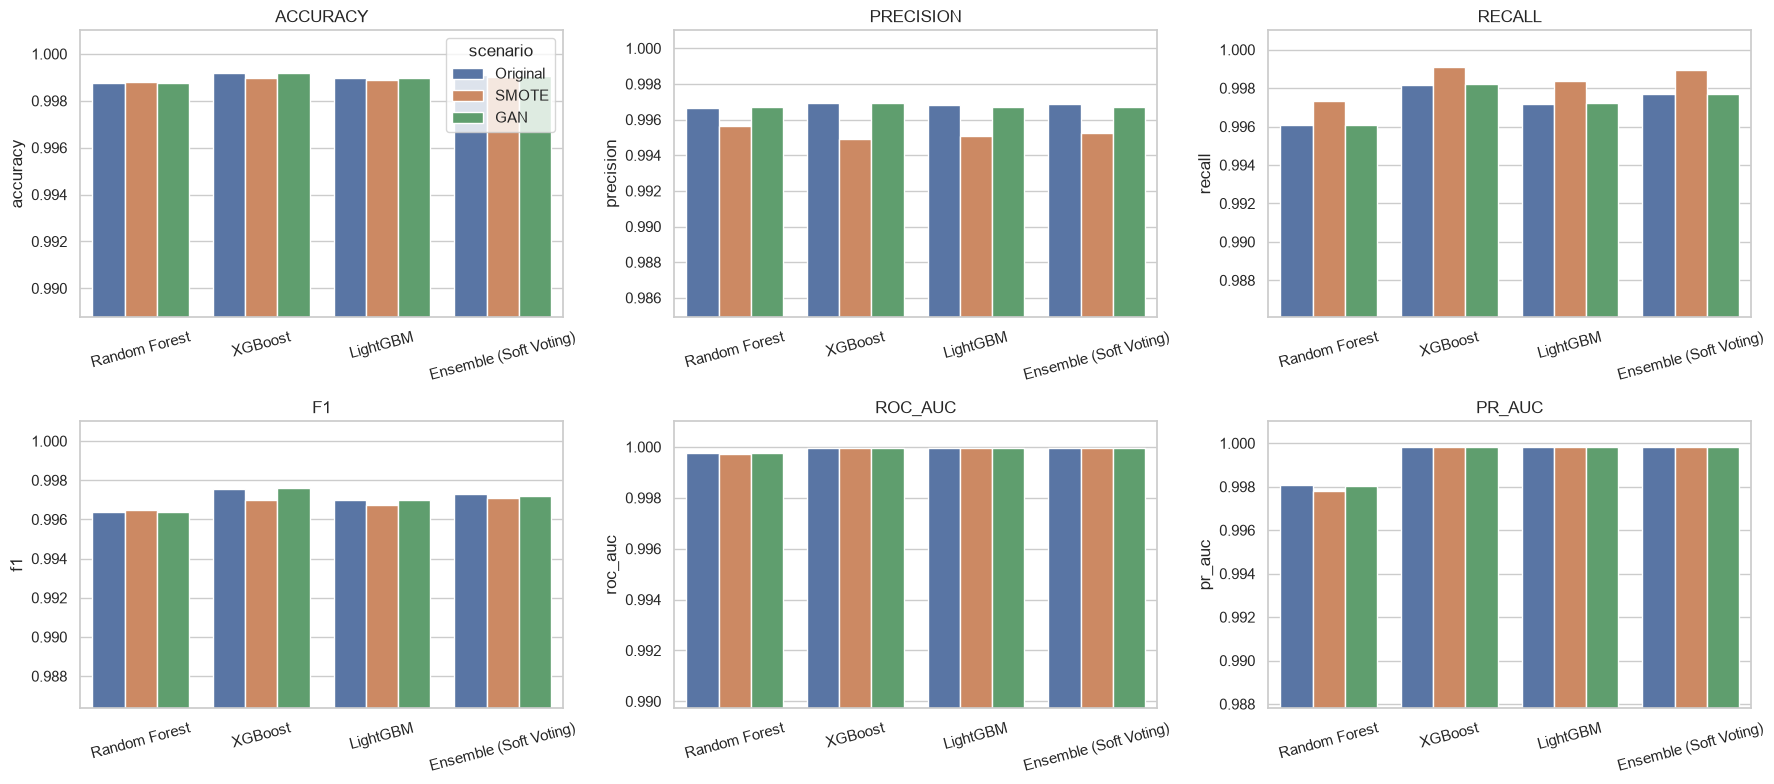

f1                 pr_auc                    mcc  \
scenario                  GAN Original  SMOTE    GAN Original  SMOTE    GAN   
model                                                                         
Ensemble (Soft Voting) 0.9972   0.9973 0.9971 0.9998   0.9998 0.9998 0.9966   
LightGBM               0.9970   0.9970 0.9967 0.9998   0.9998 0.9998 0.9964   
Random Forest          0.9964   0.9964 0.9965 0.9980   0.9981 0.9978 0.9956   
XGBoost                0.9976   0.9976 0.9970 0.9998   0.9998 0.9998 0.9971   

                                        
scenario               Original  SMOTE  
model                                   
Ensemble (Soft Voting)   0.9967 0.9965  
LightGBM                 0.9964 0.9961  
Random Forest            0.9956 0.9958  
XGBoost                  0.9971 0.9964

In [38]:
res = pd.DataFrame(results); res_val = res[res["split"] == "validation"]
compare = res_val[res_val["scenario"].isin(["Original", "SMOTE", "GAN"]) & res_val["model"].isin(TREE_NAMES + ["Ensemble (Soft Voting)"])]
metrics6 = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, mtr in zip(axes.ravel(), metrics6):
    sns.barplot(data=compare, x="model", y=mtr, hue="scenario", ax=a)
    lo = compare[mtr].min(); a.set_ylim(max(0, lo - 0.01), 1.001); a.set_title(mtr.upper()); a.set_xlabel(""); a.tick_params(axis="x", rotation=15)
    if a is not axes[0, 0]: a.get_legend().remove()
show("compare_original_smote_gan")
display(compare.pivot_table(index="model", columns="scenario", values=["f1", "pr_auc", "mcc"])[["f1", "pr_auc", "mcc"]])

## 26 · Final evaluation on the CICIDS2017 test set
First time the test set is used: every registered model is scored once, no further tuning.

,scenario,model,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc,mcc,fp,fn
0,GAN,XGBoost,0.9992,0.9967,0.9985,0.9976,0.9986,1.0000,0.9999,0.9971,208,97
1,Original,XGBoost,0.9992,0.9968,0.9983,0.9976,0.9985,1.0000,0.9999,0.9971,204,107
2,GAN + Tuned,Ensemble (Hard Voting),0.9992,0.9969,0.9982,0.9975,0.9985,0.9992,0.9966,0.9970,201,115
3,GAN + Tuned,XGBoost,0.9992,0.9967,0.9983,0.9975,0.9985,1.0000,0.9999,0.9970,211,106
4,GAN + Tuned,Ensemble (Soft Voting),0.9992,0.9968,0.9982,0.9975,0.9985,1.0000,0.9999,0.9970,203,114
5,GAN,Ensemble (Soft Voting),0.9992,0.9967,0.9983,0.9975,0.9985,1.0000,0.9999,0.9970,211,110
6,GAN + Tuned,Ensemble (Stacking),0.9991,0.9970,0.9980,0.9975,0.9985,1.0000,0.9999,0.9970,193,130
7,Original,Ensemble (Soft Voting),0.9991,0.9969,0.9981,0.9975,0.9985,1.0000,0.9999,0.9969,200,124
8,GAN,LightGBM,0.9991,0.9967,0.9981,0.9974,0.9984,1.0000,0.9999,0.9968,213,123
9,GAN + Tuned,LightGBM,0.9991,0.9965,0.9983,0.9974,0.9984,1.0000,0.9999,0.9968,227,111


FINAL MODEL = GAN + Tuned / Ensemble (Hard Voting)  (selected on validation)
              precision    recall  f1-score   support

      BENIGN     0.9996    0.9994    0.9995    314243
      ATTACK     0.9969    0.9982    0.9975     63861

    accuracy                         0.9992    378104
   macro avg     0.9982    0.9988    0.9985    378104
weighted avg     0.9992    0.9992    0.9992    378104



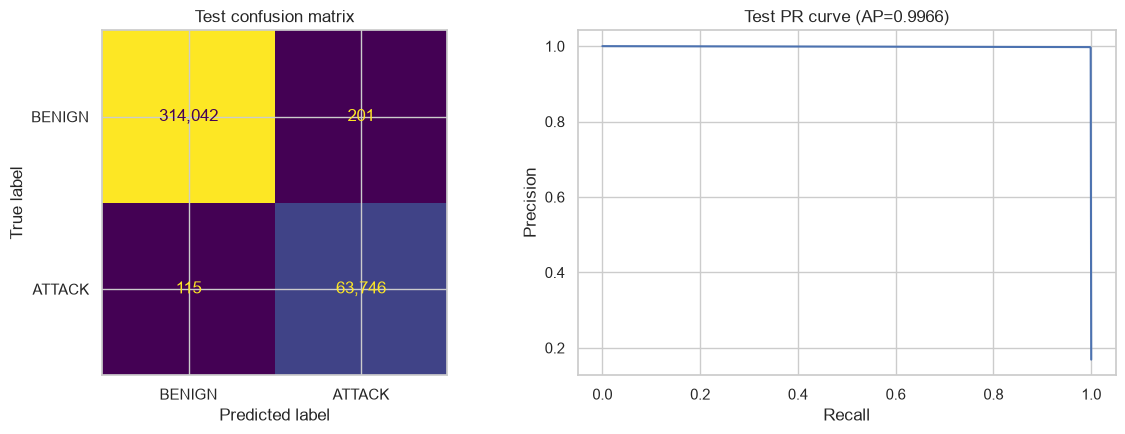

Detection rate per attack type - TEST:


,support,Original,SMOTE,GAN,GAN + Tuned (final)
type,,,,,
Heartbleed,1,0.000,0.000,0.000,0.000
Infiltration,3,0.333,0.667,0.667,0.333
Web Attack - Sql Injection,4,0.750,1.000,1.000,0.750
Web Attack - XSS,91,0.945,0.978,0.989,0.934
Web Attack - Brute Force,237,0.996,0.992,0.996,0.992
Bot,278,0.755,0.914,0.763,0.719
SSH-Patator,486,0.998,1.000,1.000,1.000
DoS Slowhttptest,740,0.996,0.996,0.996,0.996
DoS slowloris,804,0.999,1.000,0.999,1.000


In [39]:
test_rows = [evaluate(m, X_test_sel, y_test, sc, nm, "test") for (sc, nm), m in registry.items()]
results_test = pd.DataFrame(test_rows)
cols = ["scenario", "model", "accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc", "pr_auc", "mcc", "fp", "fn"]
display(results_test[cols].sort_values(["f1", "mcc"], ascending=False).reset_index(drop=True))

y_test_proba = final_model.predict_proba(X_test_sel)[:, 1]; y_test_pred = (y_test_proba >= 0.5).astype(int)
print(f"FINAL MODEL = GAN + Tuned / {FINAL_NAME}  (selected on validation)")
print(classification_report(y_test, y_test_pred, target_names=["BENIGN", "ATTACK"], digits=4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=["BENIGN", "ATTACK"], ax=ax[0], colorbar=False, values_format=",d"); ax[0].set_title("Test confusion matrix")
p_, r_, _ = precision_recall_curve(y_test, y_test_proba); ax[1].plot(r_, p_); ax[1].set(title=f"Test PR curve (AP={average_precision_score(y_test, y_test_proba):.4f})", xlabel="Recall", ylabel="Precision")
show("eval_final_test")

scen_models["GAN + Tuned (final)"] = final_model
det_test = per_type_detection(scen_models, X_test_sel, y_test, at_test.reset_index(drop=True))
print("Detection rate per attack type - TEST:")
display(det_test.style.format({c: "{:.3f}" for c in det_test.columns if c != "support"}).background_gradient(subset=[c for c in det_test.columns if c != "support"], cmap="RdYlGn", vmin=0.5, vmax=1))

## 27 · Model comparison (test set)

,label,accuracy,precision,recall,f1,roc_auc,pr_auc,mcc,fp,fn
0,Logistic Regression,0.9693,0.9274,0.8874,0.9070,0.9864,0.9464,0.8889,4436,7188
1,Decision Tree,0.9986,0.9952,0.9963,0.9957,0.9976,0.9921,0.9948,310,238
2,Random Forest,0.9989,0.9967,0.9965,0.9966,0.9998,0.9983,0.9959,209,224
3,XGBoost,0.9992,0.9968,0.9983,0.9976,1.0000,0.9999,0.9971,204,107
4,LightGBM,0.9990,0.9967,0.9976,0.9971,1.0000,0.9999,0.9966,214,151
5,Ensemble (Soft Voting),0.9991,0.9969,0.9981,0.9975,1.0000,0.9999,0.9969,200,124
6,GAN+Tuned Ens. (Hard Voting),0.9992,0.9969,0.9982,0.9975,0.9992,0.9966,0.9970,201,115


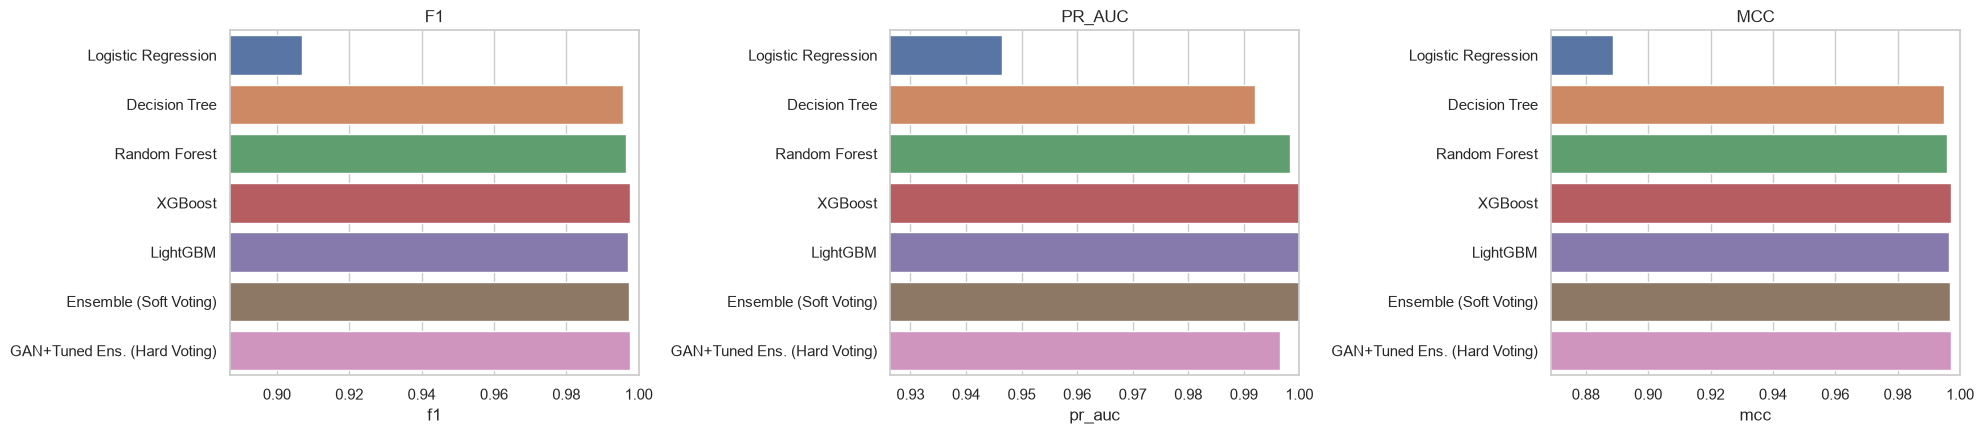

In [40]:
rows = [("Original", "Logistic Regression"), ("Original", "Decision Tree"), ("Original", "Random Forest"), ("Original", "XGBoost"),
        ("Original", "LightGBM"), ("Original", "Ensemble (Soft Voting)"), ("GAN + Tuned", FINAL_NAME)]
cmp_ = results_test.set_index(["scenario", "model"]).loc[rows].reset_index()
cmp_["label"] = np.where(cmp_["scenario"] == "Original", cmp_["model"], "GAN+Tuned " + cmp_["model"].str.replace("Ensemble ", "Ens. "))
display(cmp_[["label", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "mcc", "fp", "fn"]])
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for a, mtr in zip(ax, ["f1", "pr_auc", "mcc"]):
    sns.barplot(data=cmp_, y="label", x=mtr, ax=a, hue="label", legend=False); a.set_xlim(max(0, cmp_[mtr].min() - 0.02), 1.0); a.set_title(mtr.upper()); a.set_ylabel("")
show("model_comparison_test")

## 28 · Save final model, scaler, encoder and selected features
`ids_utils.py` (written in cell 02) must sit next to the saved files when loading them elsewhere.

In [41]:
joblib.dump(final_model, MODEL_DIR / "final_model.joblib")
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")       # signed-log + StandardScaler (fit on train only)
joblib.dump(label_encoder, MODEL_DIR / "label_encoder.joblib")
json.dump(selected_features, open(MODEL_DIR / "selected_features.json", "w"), indent=2)
json.dump(list(X_train.columns), open(MODEL_DIR / "feature_columns.json", "w"), indent=2)   # raw input columns expected
json.dump({"final_model": FINAL_NAME, "scenario": "GAN + Tuned", "gan": "WGAN-GP", "best_params": best_params, "train_rows_real": int(len(X_train)),
           "synthetic_rows": int(len(X_syn)), "random_state": RANDOM_STATE}, open(MODEL_DIR / "metadata.json", "w"), indent=2, default=str)

# reload sanity check: raw rows -> saved pipeline must reproduce the in-notebook probabilities
det = IDSDetector(MODEL_DIR)
raw_chunk = X_test.iloc[:2000]
assert np.allclose(det.predict_proba(raw_chunk), final_model.predict_proba(X_test_sel.iloc[:2000])[:, 1], atol=1e-4), "reload mismatch"
print("saved:", sorted(p.name for p in MODEL_DIR.iterdir())); print("reload check passed ->", det.predict(raw_chunk.iloc[:5]))

saved: ['feature_columns.json', 'final_model.joblib', 'label_encoder.joblib', 'metadata.json', 'preprocessor.joblib', 'selected_features.json']
reload check passed -> ['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN']


## 29 · Final results & conclusion

In [42]:
results_all = pd.concat([pd.DataFrame(results), results_test.assign(fit_time_s=np.nan)], ignore_index=True)
results_all.to_csv(OUT_DIR / "all_results.csv", index=False); det_test.to_csv(OUT_DIR / "per_attack_type_detection_test.csv")

t = results_test.set_index(["scenario", "model"])
ens = {sc: t.loc[(sc, "Ensemble (Soft Voting)")] for sc in ["Original", "SMOTE", "GAN", "GAN + Tuned"]}
print("TEST-SET SOFT-VOTING ENSEMBLE, by training scenario")
print(pd.DataFrame(ens).T[["f1", "pr_auc", "mcc", "recall", "precision", "fp", "fn"]].to_string())
d = lambda a, b, m: ens[a][m] - ens[b][m]
print(f"\nGAN vs Original : dF1 = {d('GAN','Original','f1'):+.4f}, dPR-AUC = {d('GAN','Original','pr_auc'):+.4f}, dMCC = {d('GAN','Original','mcc'):+.4f}")
print(f"GAN vs SMOTE    : dF1 = {d('GAN','SMOTE','f1'):+.4f}, dPR-AUC = {d('GAN','SMOTE','pr_auc'):+.4f}, dMCC = {d('GAN','SMOTE','mcc'):+.4f}")
best = results_test.sort_values(["mcc", "f1"], ascending=False).iloc[0]
print(f"\nBest test model by MCC: {best['scenario']} / {best['model']}  (F1={best['f1']:.4f}, MCC={best['mcc']:.4f})")
print("Top SHAP features (ensemble):", ", ".join(mean_abs.index[:8]))

TEST-SET SOFT-VOTING ENSEMBLE, by training scenario
                f1 pr_auc    mcc recall precision   fp   fn
Original    0.9975 0.9999 0.9969 0.9981    0.9969  200  124
SMOTE       0.9973 0.9999 0.9968 0.9992    0.9955  291   52
GAN         0.9975 0.9999 0.9970 0.9983    0.9967  211  110
GAN + Tuned 0.9975 0.9999 0.9970 0.9982    0.9968  203  114

GAN vs Original : dF1 = +0.0000, dPR-AUC = +0.0000, dMCC = +0.0000
GAN vs SMOTE    : dF1 = +0.0002, dPR-AUC = +0.0000, dMCC = +0.0002

Best test model by MCC: GAN / XGBoost  (F1=0.9976, MCC=0.9971)
Top SHAP features (ensemble): Bwd Packet Length Std, Destination Port, Idle Mean, Init_Win_bytes_forward, Bwd Packet Length Min, Init_Win_bytes_backward, PSH Flag Count, Fwd Packet Length Mean


### How to read / write up these results
1. **Differences are likely tiny.** CICIDS2017 binary is ~80/20 (mild imbalance) and tree ensembles already score F1 ≈ 0.99+ on the original data. Do not claim GAN "improves" anything from a 0.001 gap — a fair claim needs repeated seeds / stratified CV and a significance test (paired bootstrap or McNemar).
2. **Where the GAN can matter:** rare attack types (Infiltration, Heartbleed, SQL Injection, XSS, Web-Attack brute force) — see the per-attack-type detection tables (steps 24 and 26) and consider a *multi-class* variant.
3. **Compare on the same real data:** every scenario here uses the identical capped training split; report `TRAIN_CAP` and the GAN validation metrics (KS, AUC of real-vs-fake, NN distance) in the paper.
4. **Explainability claim:** SHAP identifies the flow features behind each decision (steps 21-22); report global, per-attack-type and local views, and note that SHAP is computed in the scaled/log feature space.
5. **Threats to validity:** duplicates removed before split; scaler / selection / GAN fit on train only; CICIDS2017 has known labelling artefacts, so confirm on UNSW-NB15 / NSL-KDD.